<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/VQC_MalwareFeatureEngineering_Liu2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC and QSVM with feature engineering for Android malware detection: Liu, Eren and Nicholas (2023) step by step

**Paper.** Ran Liu, Maksim Eren, Charles Nicholas (University of Maryland, Baltimore County). *Can Feature Engineering Help Quantum Machine Learning for Malware Detection?* arXiv:2305.02396 (cs.LG), v2, 9 August 2023. DOI: [10.48550/arXiv.2305.02396](https://doi.org/10.48550/arXiv.2305.02396).

**What this notebook does.** The paper is a four-page preliminary study. A quantum computer (here: a simulator) has only a few qubits, but an Android app is described by 215 yes/no features. The authors ask whether a *classical* feature-selection step (keep only the most important features, one feature per qubit) lets a quantum classifier detect malware, and whether re-balancing the training data (over-sampling and under-sampling) helps further. The notebook re-runs every experiment the paper describes with Qiskit:

1. feature selection with **XGBoost** and with a **decision tree**, then a **Variational Quantum Classifier (VQC)** on 10,000 apps with a 50 % test split;
2. a **quantum-kernel SVM (QSVM)** on 20 random apps, repeated ten times, with a 95 % confidence interval;
3. **SMOTE, ADASYN, K-means under-sampling, neighbourhood-based cleaning and their combination** before the QSVM;
4. the "IBM 5-qubit machine" experiment, which we replace by a *noisy simulation* of a 5-qubit IBM device (no real hardware is used here).

Every quantum result is shown next to a classical baseline (random forest, RBF-SVM, XGBoost) trained on exactly the same selected features.

**How to run.** Open in Google Colab, choose a CPU runtime and press *Runtime -> Run all*. With `FAST_MODE = True` (the setting stored in the cell below) the run is a class demonstration of about 10 minutes; with `FAST_MODE = False` it uses the larger budgets listed in the configuration cell. The data (a 6.5 MB CSV from figshare) are downloaded inside the notebook; no account or token is needed (the notebook does not use a Hugging Face token).

**What you get at the end.** Plots of the real data, drawings of the circuits that are executed, a table that puts the paper's numbers next to ours with a verdict per claim, and a critical reading of the paper.

## The paper in one page

* **Problem.** Supervised malware classifiers need frequent re-training, which is slow. Quantum machine learning may help in theory, but gate-model machines (IBM Quantum) have very few qubits, so the 215-dimensional app description cannot be loaded as it is.
* **Idea.** Use a classical model (XGBoost or a decision tree) to rank the features and keep only the **top 20**, so that the data fit the qubits. Then train a quantum classifier on those features.
* **Data.** The Drebin Android malware dataset: more than 15 k benign and malware apps, 215 binary features (static and dynamic: permissions, API calls, intents ...), reference DroidFusion (Yerima and Sezer, 2019).
* **Quantum models.** The Variational Quantum Classifier of Havlicek et al. (2019): data are mapped by the second-order Pauli-Z ("ZZ") feature map, followed by a layered variational circuit, Z-basis measurement and a bit-string-to-label rule; and the quantum-kernel SVM of the same paper (the quantum computer estimates the kernel between all data pairs).
* **Claims (Section 5).**
  1. VQC, XGBoost features, 10,000 samples, 50 % test split: **78.91 %** test accuracy; with decision-tree features: **62.41 %**.
  2. QSVM on an IBM 5-qubit setting, ten runs of 20 random samples (50 % split), XGBoost features: **74 % (95 % CI +-11.35 %)**.
  3. Re-balancing raises the 74 % to: SMOTE **80.15 %**, ADASYN **78.06 %**, K-means under-sampling **78.62 %**, neighbourhood-based removal **77.26 %**, over- plus under-sampling combined **83.78 %**.
  4. On the real IBM 5-qubit machine (20 samples, 50 % split): QSVM **56 %**, VQC **80 %**.
* **What the paper does not say** (the notebook has to choose): the VQC ansatz and its depth, the optimiser and its budget, the number of shots, the readout rule, how the binary features are turned into angles, the XGBoost and tree settings, what exactly "neighbourhood-based removal" and "combined" mean, on which model and sample size the re-balancing was tested, and which IBM device was used.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data | Drebin, > 15 k apps, 215 features | Drebin-215 from figshare (Yerima), 15,036 rows, 5 rows with a "?" value dropped -> 15,031 apps (9,476 benign `B`, 5,555 malware `S`); the file in the paper's own reference [10] |
| Feature selection | XGBoost / decision tree, top 20 | same two selectors, importances fitted **on the training half only**, **top-k with k = number of qubits** (`N_QUBITS`; 20 qubits cannot be simulated on a laptop, see below) |
| Extra variants | none | random forest, ANOVA F, correlation, "first k columns" and "random k columns" as controls |
| VQC circuit | Havlicek ZZ feature map + l layers | `zz_feature_map(reps=2, entanglement="linear")` + `real_amplitudes(reps=3)` (the Qiskit defaults of the time); `# CHOICE:` |
| Readout | Z-basis, bit string -> label | Qiskit `VQC` rule: label = least significant bit of the measured bit string (parity of one qubit), cross-entropy loss; `# CHOICE:` |
| Optimiser | not given | COBYLA, `MAXITER` evaluations; `# CHOICE:` |
| Shots | not given | exact probabilities (infinite shots) from an exact simulator that is checked against the stock Qiskit `VQC`; `# CHOICE:` |
| Angles | "(0, 2 pi]" | binary feature x in {0,1} -> angle x * pi/2 for the VQC; the QSVM scale is chosen on a validation split; the range [0, pi] would make the ZZ terms vanish (shown below); `# CHOICE:` |
| Sample size and split | 10,000 samples, 50 % test | the same (FAST: smaller), stratified split, 3 repeats with different seeds (FAST: 2) |
| QSVM | IBM 5-qubit machine, 10 runs x 20 samples, 95 % CI | 5-qubit exact kernel simulator, 10 runs x 20 samples, 95 % CI (t-interval); features chosen on a development part that never contains the 20 samples |
| Re-balancing | SMOTE, ADASYN, K-means, neighbourhood cleaning, combined | `imbalanced-learn`: `SMOTE`, `ADASYN`, `ClusterCentroids`, `EditedNearestNeighbours`, `SMOTEENN`, `SMOTETomek`, applied to the training split only; tested at the paper's scale (20 samples) and at a larger scale |
| Real hardware | IBM 5-qubit machine | not available; replaced by a **noisy simulation** with the noise model of `FakeManilaV2` (5 qubits, qiskit-ibm-runtime fake provider). This is not the same device and not the same day. |
| Baselines | none | RandomForest, SVC (RBF), XGBoost, majority class, on the identical inputs |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_need = [m for m in ["qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime", "xgboost", "imblearn"] if importlib.util.find_spec(m) is None]
if IN_COLAB or _need:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc "xgboost==3.4.1" "imbalanced-learn==0.14.2"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("All required packages already present; skipping pip install.")

All required packages already present; skipping pip install.


In [2]:
# ---- Configuration: every tunable constant lives here ------------------------------------------
SEED = 42
FAST_MODE = False              # True: class demo (about 10 min). False: larger budgets (see the comments)

# Experiment 1: VQC on XGBoost / decision-tree selected features (paper: 20 qubits, 10,000 samples, 50 % test)
N_QUBITS = 6 if FAST_MODE else 8           # CHOICE: paper keeps 20 features; 20 qubits are out of reach for an exact simulator on a laptop
N_TOTAL = 3000 if FAST_MODE else 10000     # paper: 10,000 samples
TEST_SIZE = 0.5                            # paper: 50 % test split
N_SEEDS = 2 if FAST_MODE else 3            # repeats with different random samples/splits (paper: one run)
MAXITER = 40 if FAST_MODE else 100         # CHOICE: COBYLA evaluations for the VQC (paper: not given)
VARIANTS = ["xgboost", "decision_tree", "random_forest", "random"] if FAST_MODE else \
           ["xgboost", "decision_tree", "random_forest", "f_classif", "correlation", "first", "random"]
QUBIT_SWEEP = [4, 6] if FAST_MODE else [4, 6, 8, 10]   # how many selected features/qubits (seed 0 only)
ANGLE_VQC = 3.141592653589793 / 2          # CHOICE: binary feature 0/1 -> angle 0 / pi/2

# Experiments 2-4: the "IBM 5-qubit" protocol (paper: 5 qubits, 20 samples, 10 runs)
HW_QUBITS = 5
HW_SAMPLES = 20
HW_RUNS = 10
RS_SAMPLES = 100 if FAST_MODE else 200     # CHOICE: a second, larger scale for the re-balancing study
RS_RUNS = 5 if FAST_MODE else 10
NOISY_RUNS = 3 if FAST_MODE else 10        # runs repeated on the noisy-device simulation
NOISE_SHOTS = 1024

DATA_DIR = "drebin_data"       # downloaded file is cached here
LOCAL_CSV = ""                 # optional: path of an uploaded copy of the Drebin-215 CSV
IBM_TOKEN = ""                 # not used: no real quantum hardware is called in this notebook

In [3]:
import os, io, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from scipy import stats
warnings.filterwarnings("ignore")
T_START = time.time()

import sklearn, xgboost, imblearn
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import f_classif
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.under_sampling import ClusterCentroids, EditedNearestNeighbours
from imblearn.combine import SMOTEENN, SMOTETomek

import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector
from qiskit.primitives import StatevectorSampler
from qiskit_aer import AerSimulator
from qiskit_machine_learning.algorithms import VQC, QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_ibm_runtime.fake_provider import FakeManilaV2

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| imbalanced-learn", imblearn.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__)
print("FAST_MODE =", FAST_MODE, "| N_QUBITS =", N_QUBITS, "| N_TOTAL =", N_TOTAL, "| N_SEEDS =", N_SEEDS, "| MAXITER =", MAXITER)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
scikit-learn 1.9.1 | xgboost 3.4.1 | imbalanced-learn 0.14.2
numpy 2.5.4 | pandas 3.0.6
FAST_MODE = False | N_QUBITS = 8 | N_TOTAL = 10000 | N_SEEDS = 3 | MAXITER = 100


## 1. Getting the data

The paper uses the Drebin dataset in the form described in the DroidFusion paper (reference [10]): one row per Android app, 215 binary columns that say whether a feature is present (a permission such as `SEND_SMS`, an API call such as `TelephonyManager.getDeviceId`, a system command such as `chmod` ...), and a `class` column (`B` = benign, `S` = malware). That 215-feature table is published by Suleiman Yerima on figshare ("Android malware dataset for machine learning 2") and is downloaded below. Five rows contain a "?" instead of a number; they are dropped.

In [4]:
FIG_URLS = ["https://ndownloader.figshare.com/files/10391991", "https://figshare.com/ndownloader/files/10391991"]

def fetch(urls, path, min_bytes, first_token):
    if os.path.exists(path) and os.path.getsize(path) >= min_bytes:
        return path
    last = None
    for u in urls:
        try:
            r = requests.get(u, stream=True, timeout=90)
            r.raise_for_status()
            buf = b"".join(r.iter_content(65536))
            if len(buf) >= min_bytes and buf[:60].decode("utf-8", "ignore").startswith(first_token):
                with open(path, "wb") as f:
                    f.write(buf)
                return path
            last = f"unexpected content from {u}"
        except Exception as e:
            last = f"{u}: {e}"
    raise RuntimeError("Could not download the dataset (" + str(last) + "). Upload the CSV and set LOCAL_CSV.")

csv_path = LOCAL_CSV or fetch(FIG_URLS, os.path.join(DATA_DIR, "drebin215.csv"), 1_000_000, "transact")
raw = pd.read_csv(csv_path, low_memory=False)
raw.columns = [c.strip() for c in raw.columns]
print("raw file:", raw.shape, "| file size %.1f MB" % (os.path.getsize(csv_path) / 1e6))

feat_cols = [c for c in raw.columns if c != "class"]
Xnum = raw[feat_cols].apply(pd.to_numeric, errors="coerce")
bad_rows = Xnum.isna().any(axis=1)
print("rows with a non-numeric value ('?'):", int(bad_rows.sum()), "-> dropped")
X_all = Xnum[~bad_rows].astype(float).reset_index(drop=True)
y_all = (raw.loc[~bad_rows, "class"].astype(str).str.strip() == "S").astype(int).values     # 1 = malware = positive class
print("clean data:", X_all.shape, "| malware:", int(y_all.sum()), "| benign:", int((y_all == 0).sum()),
      "| majority-class accuracy: %.4f" % (1 - y_all.mean()))
print("all values binary:", bool(np.isin(X_all.values, [0.0, 1.0]).all()),
      "| exact duplicate rows:", int(pd.concat([X_all, pd.Series(y_all, name="y")], axis=1).duplicated().sum()), "(kept)")

# Development part (feature selection, bandwidth tuning, the figures) and hold-out part (the 20-sample draws of experiments 2-4)
DEV_IDX, HOLD_IDX = train_test_split(np.arange(len(X_all)), test_size=0.3, stratify=y_all, random_state=SEED)
Xdev, ydev = X_all.iloc[DEV_IDX].reset_index(drop=True), y_all[DEV_IDX]
Xhold, yhold = X_all.iloc[HOLD_IDX].reset_index(drop=True), y_all[HOLD_IDX]
print("development part:", Xdev.shape, "| hold-out part:", Xhold.shape)

raw file: (15036, 216) | file size 6.5 MB


rows with a non-numeric value ('?'): 5 -> dropped
clean data: (15031, 215) | malware: 5555 | benign: 9476 | majority-class accuracy: 0.6304


all values binary: True | exact duplicate rows: 7772 (kept)


development part: (10521, 215) | hold-out part: (4510, 215)


## Dataset Exploration and Visualisation

Before any model is trained, look at the real data. The cells below print the shape, the feature names and the original labels with their counts, plot the real class distribution, and draw two-dimensional scatter plots in which **every point is a real app coloured by its true label** (blue = benign `B`, red = malware `S`). Drebin-215 only has these two labels (no malware family is given in this file), so the colouring is binary. The first plot uses all 215 features (PCA fitted on the training/development part only); the second uses the features the quantum model actually sees, after the angle encoding.

Dataset shape (rows, feature columns + label): (15036, 216) | after cleaning: (15031, 215)
Number of features: 215 (each is 0/1: absent/present)
First 15 feature names: ['transact', 'onServiceConnected', 'bindService', 'attachInterface', 'ServiceConnection', 'android.os.Binder', 'SEND_SMS', 'Ljava.lang.Class.getCanonicalName', 'Ljava.lang.Class.getMethods', 'Ljava.lang.Class.cast', 'Ljava.net.URLDecoder', 'android.content.pm.Signature', 'android.telephony.SmsManager', 'READ_PHONE_STATE', 'getBinder']
Last 5 feature names:   ['WRITE_EXTERNAL_STORAGE', 'ACCESS_FINE_LOCATION', 'SET_WALLPAPER_HINTS', 'SET_PREFERRED_APPLICATIONS', 'WRITE_SECURE_SETTINGS']

Original label values in the CSV `class` column: ['B', 'S'] (S = malware, B = benign)
class
B    9476
S    5560



Fraction of features set per app (median, min, max): 0.15348837209302327 0.0 0.5255813953488372


,transact,onServiceConnected,bindService,attachInterface,ServiceConnection,android.os.Binder,SEND_SMS,Ljava.lang.Class.getCanonicalName,Ljava.lang.Class.getMethods,Ljava.lang.Class.cast,y
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1


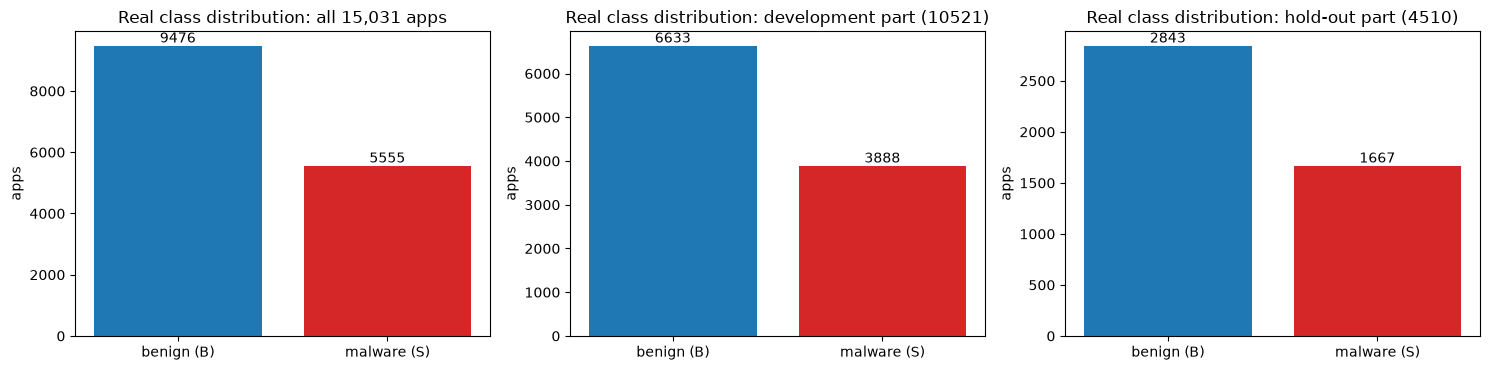

In [5]:
print("Dataset shape (rows, feature columns + label):", raw.shape, "| after cleaning:", X_all.shape)
print("Number of features:", len(feat_cols), "(each is 0/1: absent/present)")
print("First 15 feature names:", feat_cols[:15])
print("Last 5 feature names:  ", feat_cols[-5:])
print("\nOriginal label values in the CSV `class` column:", sorted(raw["class"].astype(str).str.strip().unique()), "(S = malware, B = benign)")
print(raw["class"].astype(str).str.strip().value_counts().to_string())
print("\nFraction of features set per app (median, min, max):", float(X_all.mean(axis=1).median()), float(X_all.mean(axis=1).min()), float(X_all.mean(axis=1).max()))
display(X_all.iloc[:5, :10].assign(y=y_all[:5]))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (name, yy) in zip(axes, [("all 15,031 apps", y_all), (f"development part ({len(ydev)})", ydev), (f"hold-out part ({len(yhold)})", yhold)]):
    cnt = pd.Series(yy).map({0: "benign (B)", 1: "malware (S)"}).value_counts().reindex(["benign (B)", "malware (S)"])
    ax.bar(cnt.index, cnt.values, color=["tab:blue", "tab:red"])
    for i, v in enumerate(cnt.values): ax.text(i, v, str(v), ha="center", va="bottom")
    ax.set_title("Real class distribution: " + name); ax.set_ylabel("apps")
plt.tight_layout(); plt.show()

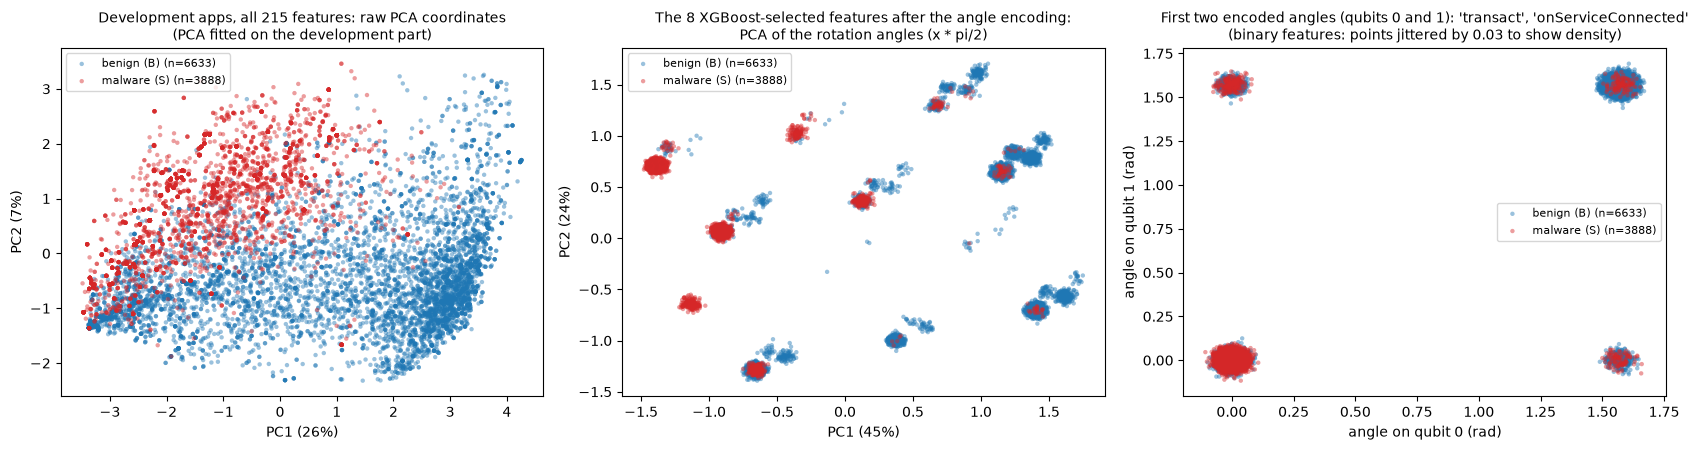

8 features selected by XGBoost on the development part: ['transact', 'onServiceConnected', 'READ_PHONE_STATE', 'DELETE_CACHE_FILES', 'SEND_SMS', 'CLEAR_APP_CACHE', 'MANAGE_ACCOUNTS', 'MODIFY_AUDIO_SETTINGS']


In [6]:
def scatter_by_class(ax, Z, y, title, xl, yl, jitter=0.0, seed=SEED, s=10):
    r = np.random.default_rng(seed)
    for lab, name, col in [(0, "benign (B)", "tab:blue"), (1, "malware (S)", "tab:red")]:
        m = y == lab
        pts = Z[m] + (r.normal(0, jitter, Z[m].shape) if jitter else 0)
        ax.scatter(pts[:, 0], pts[:, 1], s=s, alpha=0.45, c=col, label=f"{name} (n={m.sum()})", edgecolors="none")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend(fontsize=8)

# the feature selectors used throughout (defined here so that the figure can use the XGBoost features)
def select_features(method, Xtr, ytr, k, seed):
    """Return the k most important columns, with every importance fitted on the TRAINING rows only."""
    if method == "xgboost":
        m = XGBClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr, ytr)
        imp = pd.Series(m.feature_importances_, index=Xtr.columns)
    elif method == "decision_tree":
        m = DecisionTreeClassifier(random_state=seed).fit(Xtr, ytr)
        imp = pd.Series(m.feature_importances_, index=Xtr.columns)
    elif method == "random_forest":
        m = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr, ytr)
        imp = pd.Series(m.feature_importances_, index=Xtr.columns)
    elif method == "f_classif":
        f, _ = f_classif(Xtr, ytr); imp = pd.Series(np.nan_to_num(f), index=Xtr.columns)
    elif method == "correlation":
        imp = Xtr.corrwith(pd.Series(ytr, index=Xtr.index)).abs().fillna(0.0)
    elif method == "first":
        imp = pd.Series(-np.arange(Xtr.shape[1], dtype=float), index=Xtr.columns)
    elif method == "random":
        imp = pd.Series(np.random.default_rng(seed).random(Xtr.shape[1]), index=Xtr.columns)
    else:
        raise ValueError(method)
    return list(imp.sort_values(ascending=False, kind="mergesort").index[:k]), imp

pca_all = PCA(n_components=2, random_state=SEED).fit(Xdev)
sel_dev, imp_dev = select_features("xgboost", Xdev, ydev, N_QUBITS, SEED)
A_dev = Xdev[sel_dev].values * ANGLE_VQC
pca_ang = PCA(n_components=2, random_state=SEED).fit(A_dev)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
scatter_by_class(axes[0], pca_all.transform(Xdev), ydev, "Development apps, all 215 features: raw PCA coordinates\n(PCA fitted on the development part)",
                 f"PC1 ({pca_all.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca_all.explained_variance_ratio_[1]:.0%})")
scatter_by_class(axes[1], pca_ang.transform(A_dev), ydev, f"The {N_QUBITS} XGBoost-selected features after the angle encoding:\nPCA of the rotation angles (x * pi/2)",
                 f"PC1 ({pca_ang.explained_variance_ratio_[0]:.0%})", f"PC2 ({pca_ang.explained_variance_ratio_[1]:.0%})", jitter=0.03)
scatter_by_class(axes[2], A_dev[:, :2], ydev, f"First two encoded angles (qubits 0 and 1): '{sel_dev[0]}', '{sel_dev[1]}'\n(binary features: points jittered by 0.03 to show density)",
                 "angle on qubit 0 (rad)", "angle on qubit 1 (rad)", jitter=0.03)
plt.tight_layout(); plt.show()
print(f"{N_QUBITS} features selected by XGBoost on the development part:", sel_dev)

**How to read these pictures.** Malware (red) and benign apps (blue) overlap in the first two principal components of all 215 features, but they are not mixed completely: the red cloud is shifted and spreads along directions that the benign apps do not use. After keeping only the selected features the data are even coarser: each qubit sees one of only two angles (0 or pi/2), so the whole development set collapses onto at most 2^k distinct points (the jitter makes their multiplicity visible). This is the real difficulty the paper wants to relieve with feature engineering: how much information survives in the few features that fit on the qubits?

## 2. Feature engineering: which features reach the qubits?

This is the paper's central step. A classical model ranks the 215 features by importance and only the best `k` are kept, one per qubit. The paper uses **XGBoost** and a **decision tree** (`k = 20`). Here the selectors are fitted on the training rows only; the same functions are reused by every experiment. Besides the two selectors of the paper the notebook also evaluates a few other selectors and two controls ("first k columns", "random k columns") so that we can tell whether *good* selection or *any* selection matters.

,nonzero_importance,selected
selector,,
xgboost,144,"transact, onServiceConnected, READ_PHONE_STATE..."
decision_tree,134,"transact, READ_PHONE_STATE, SEND_SMS, Telephon..."
random_forest,213,"SEND_SMS, android.telephony.SmsManager, androi..."
f_classif,215,"transact, onServiceConnected, bindService, Ser..."
correlation,215,"transact, onServiceConnected, bindService, Ser..."
first,0,"transact, onServiceConnected, bindService, att..."
random,215,"INSTALL_LOCATION_PROVIDER, android.os.Binder, ..."


,xgboost,decision_tree,random_forest,f_classif,correlation,first,random
xgboost,1.00,0.33,0.33,0.23,0.23,0.23,0.00
decision_tree,0.33,1.00,0.23,0.23,0.23,0.23,0.00
random_forest,0.33,0.23,1.00,0.60,0.60,0.60,0.07
f_classif,0.23,0.23,0.60,1.00,1.00,1.00,0.07
correlation,0.23,0.23,0.60,1.00,1.00,1.00,0.07
first,0.23,0.23,0.60,1.00,1.00,1.00,0.07
random,0.00,0.00,0.07,0.07,0.07,0.07,1.00


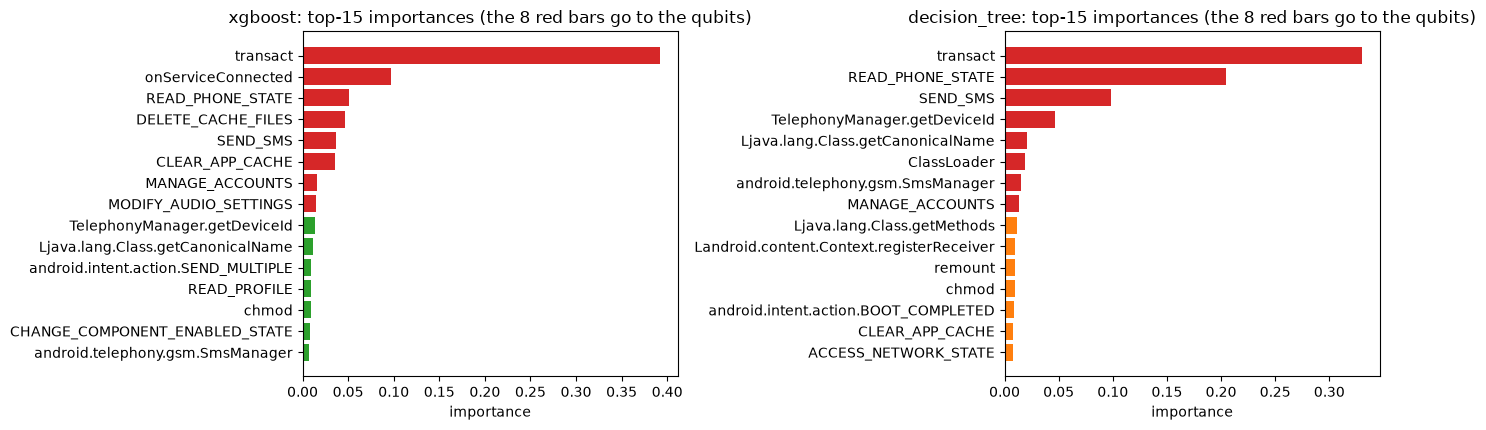

In [7]:
rows = []
sel_sets = {}
for v in ["xgboost", "decision_tree", "random_forest", "f_classif", "correlation", "first", "random"]:
    cols, imp = select_features(v, Xdev, ydev, N_QUBITS, SEED)
    sel_sets[v] = cols
    rows.append(dict(selector=v, nonzero_importance=int((imp > 0).sum()), selected=", ".join(cols)))
display(pd.DataFrame(rows).set_index("selector"))
names = list(sel_sets)
jac = pd.DataFrame([[len(set(sel_sets[a]) & set(sel_sets[b])) / len(set(sel_sets[a]) | set(sel_sets[b])) for b in names] for a in names], index=names, columns=names)
display(jac.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, v, col in zip(axes, ["xgboost", "decision_tree"], ["tab:green", "tab:orange"]):
    cols, imp = select_features(v, Xdev, ydev, 15, SEED)
    ax.barh(cols[::-1], imp[cols].values[::-1], color=["tab:red" if i < N_QUBITS else col for i in range(15)][::-1])
    ax.set_title(f"{v}: top-15 importances (the {N_QUBITS} red bars go to the qubits)"); ax.set_xlabel("importance")
plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

The paper's quantum classifier is the VQC of Havlicek et al. The data point is loaded by the **ZZ feature map** `U_Phi(x) H^n U_Phi(x) H^n` (Hadamards, single-qubit phases `phi_i(x) = x_i` and two-qubit phases `phi_ij(x) = (pi - x_i)(pi - x_j)` realised with CNOT-phase-CNOT blocks); then comes a layered trainable circuit; then the qubits are measured. The paper does not give the trainable part, so the Qiskit defaults of the time are used (`# CHOICE:`): `zz_feature_map(n, reps=2, entanglement="linear")` followed by `real_amplitudes(n, reps=3)` (RY rotations and a CNOT ladder, `reps+1` rotation layers). Qiskit's `VQC` measures all qubits and labels a shot by the least significant bit of the bit string (`x % 2`), so the class probability is the probability that qubit 0 is measured as 1; the loss is the cross-entropy.

The exact simulator below does not call the slow shot-based sampler; it produces the *same* probabilities by computing the feature-map state once per distinct app (the features are binary, so there are at most `2^k` distinct apps) and applying the ansatz as a gate list taken from the executed circuit. The two cells after the drawings **assert** that this simulator agrees with Qiskit's own `Statevector` and with the stock `VQC` network. Architecture 1 is the VQC with `N_QUBITS` qubits (experiment 1), architecture 2 the 5-qubit VQC of the "IBM 5-qubit" protocol, architecture 3 the compute-uncompute circuit that estimates one QSVM kernel entry.

Architecture 1, VQC with 8 qubits: qubits = 8 | depth = 46 (in H/P/CX/RY gates: 46) | gates = {'cx': 49, 'ry': 32, 'p': 30, 'h': 16} | trainable parameters = 32 | data parameters = 8


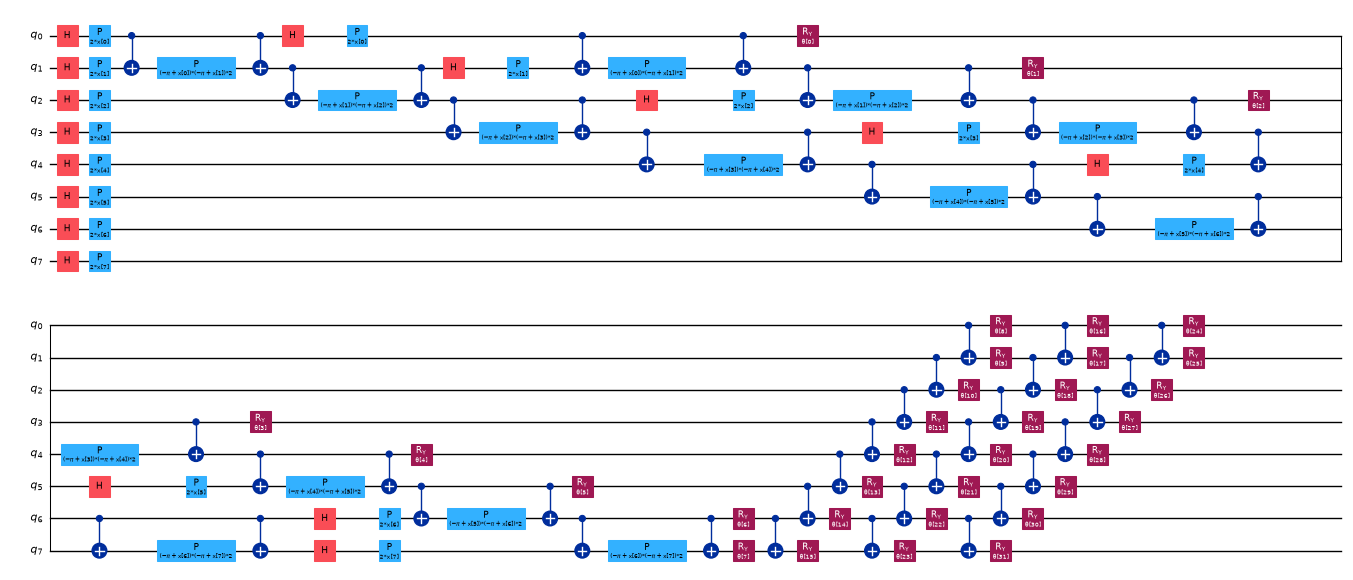

Architecture 1 as drawn in blocks (feature map | ansatz) with the measurement that the sampler adds:


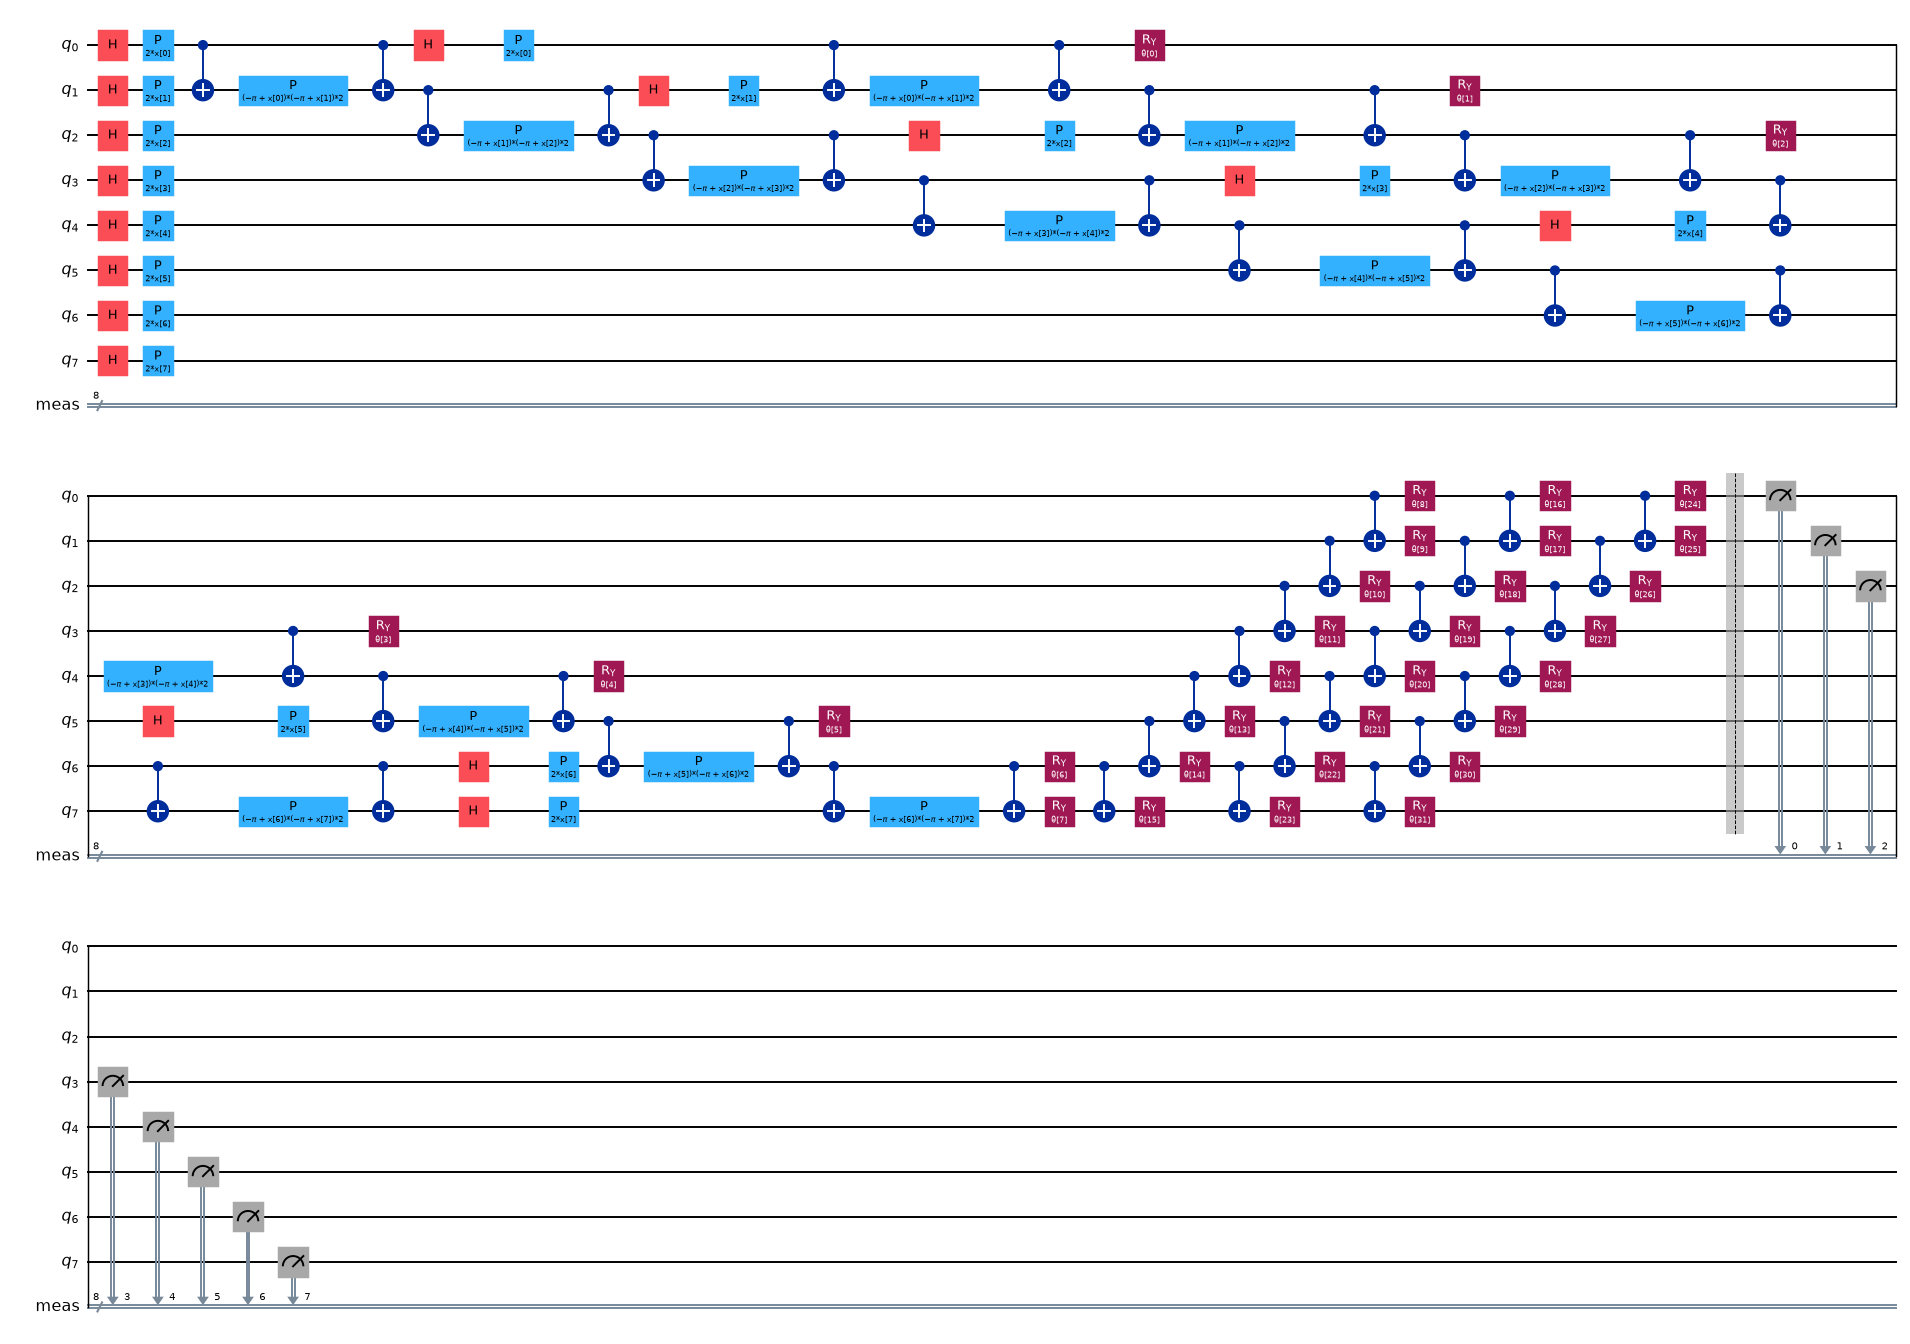

In [8]:
class QuantumModelKit:
    """ZZ feature map + RealAmplitudes on n qubits, with an exact batched simulator (checked against Qiskit below)."""
    def __init__(self, n, fm_reps=2, fm_ent="linear", an_reps=3):
        self.n = n
        self.fm = zz_feature_map(n, reps=fm_reps, entanglement=fm_ent)    # CHOICE: reps=2, linear entanglement
        self.an = real_amplitudes(n, reps=an_reps)                        # CHOICE: reps=3
        self.qc = QuantumCircuit(n); self.qc.compose(self.fm, inplace=True); self.qc.compose(self.an, inplace=True)
        self._sim = AerSimulator(method="statevector", max_parallel_threads=1)
        fms = self.fm.copy(); fms.save_statevector()
        self._fmT = transpile(fms, self._sim, optimization_level=0)
        flat = self.an.decompose(); widx = {p: i for i, p in enumerate(self.an.parameters)}
        idx = np.arange(2 ** n); prog = []
        for ins in flat.data:                      # the ansatz as a gate list read from the executed circuit
            q = [flat.find_bit(b).index for b in ins.qubits]
            if ins.operation.name == "cx":
                perm = idx.copy(); m = ((idx >> q[0]) & 1) == 1; perm[m] = idx[m] ^ (1 << q[1])
                if prog and prog[-1][0] == "perm": prog[-1] = ("perm", prog[-1][1][perm])
                else: prog.append(("perm", perm))
            elif ins.operation.name == "r":        # r(theta, pi/2) == RY(theta)
                assert abs(float(ins.operation.params[1]) - np.pi / 2) < 1e-12
                prog.append(("ry", q[0], widx[ins.operation.params[0]]))
            else:
                raise ValueError("unexpected gate " + ins.operation.name)
        self.prog = prog
        self.q0_is_one = ((np.arange(2 ** n) & 1) == 1)       # qubit 0 = least significant bit of the bit string

    def feature_states(self, X):
        """Feature-map state of every distinct row of X. Returns (states, inverse index back to the rows of X)."""
        X = np.asarray(X, float)
        Xu, inv = np.unique(X, axis=0, return_inverse=True)
        res = self._sim.run(self._fmT, parameter_binds=[{p: Xu[:, i].tolist() for i, p in enumerate(self.fm.parameters)}]).result()
        return np.array([res.get_statevector(i) for i in range(len(Xu))]), inv.ravel()

    def apply_ansatz(self, S, w):
        n = self.n; B = S.shape[0]
        R = np.concatenate([S.real, S.imag], axis=0)          # the ansatz is real: real and imaginary parts evolve identically
        for st in self.prog:
            if st[0] == "perm":
                R = R[:, st[1]]
            else:
                _, q, kk = st; th = w[kk] / 2; c, s = np.cos(th), np.sin(th)
                V = R.reshape(R.shape[0], 2 ** (n - 1 - q), 2, 2 ** q)
                a0, a1 = V[:, :, 0, :], V[:, :, 1, :]
                W = np.empty_like(V); W[:, :, 0, :] = c * a0 - s * a1; W[:, :, 1, :] = s * a0 + c * a1
                R = W.reshape(R.shape[0], -1)
        return R[:B] + 1j * R[B:]

    def class_probs(self, S, w):
        P = np.abs(self.apply_ansatz(S, w)) ** 2
        p1 = P[:, self.q0_is_one].sum(1)
        return np.stack([1 - p1, p1], 1)

    def gram(self, XA, XB=None):
        """Fidelity kernel |<phi(a)|phi(b)>|^2 between the rows of XA and XB (angles already applied)."""
        SA, ia = self.feature_states(XA)
        SB, ib = (SA, ia) if XB is None else self.feature_states(XB)
        K = np.abs(SA.conj() @ SB.T) ** 2
        return K[np.ix_(ia, ib)]

def make_fast_qnn(kit):
    class FastSamplerQNN(SamplerQNN):
        """SamplerQNN whose forward pass is the exact batched simulation above (same circuit, same readout)."""
        _ck = None; _cache = None
        def _forward(self, input_data, weights):
            X = np.asarray(input_data, float).reshape(-1, kit.n)
            key = (X.shape, hash(X.tobytes()))
            if key != self._ck:
                self._cache = kit.feature_states(X); self._ck = key
            S, inv = self._cache
            return kit.class_probs(S, np.asarray(weights, float).ravel())[inv]
    return FastSamplerQNN

kit = QuantumModelKit(N_QUBITS)          # architecture 1: experiment 1
kit5 = QuantumModelKit(HW_QUBITS)        # architecture 2: the 5-qubit protocol
FastQNN, FastQNN5 = make_fast_qnn(kit), make_fast_qnn(kit5)

def describe(name, qc, n_params_train, n_params_input):
    basis = transpile(qc, basis_gates=["h", "p", "cx", "ry"], optimization_level=0)
    print(f"{name}: qubits = {qc.num_qubits} | depth = {qc.depth()} (in H/P/CX/RY gates: {basis.depth()}) | gates = {dict(basis.count_ops())}"
          f" | trainable parameters = {n_params_train} | data parameters = {n_params_input}")
    return basis

# ----- Architecture 1
b1 = describe(f"Architecture 1, VQC with {N_QUBITS} qubits", kit.qc, kit.an.num_parameters, kit.fm.num_parameters)
qc1 = kit.qc.copy(); qc1.measure_all()
fig = b1.draw("mpl", fold=40, scale=0.5); display(fig); plt.close(fig)
print("Architecture 1 as drawn in blocks (feature map | ansatz) with the measurement that the sampler adds:")
fig = qc1.draw("mpl", fold=40, scale=0.7); display(fig); plt.close(fig)

Architecture 2, VQC with 5 qubits: qubits = 5 | depth = 34 (in H/P/CX/RY gates: 34) | gates = {'cx': 28, 'ry': 20, 'p': 18, 'h': 10} | trainable parameters = 20 | data parameters = 5


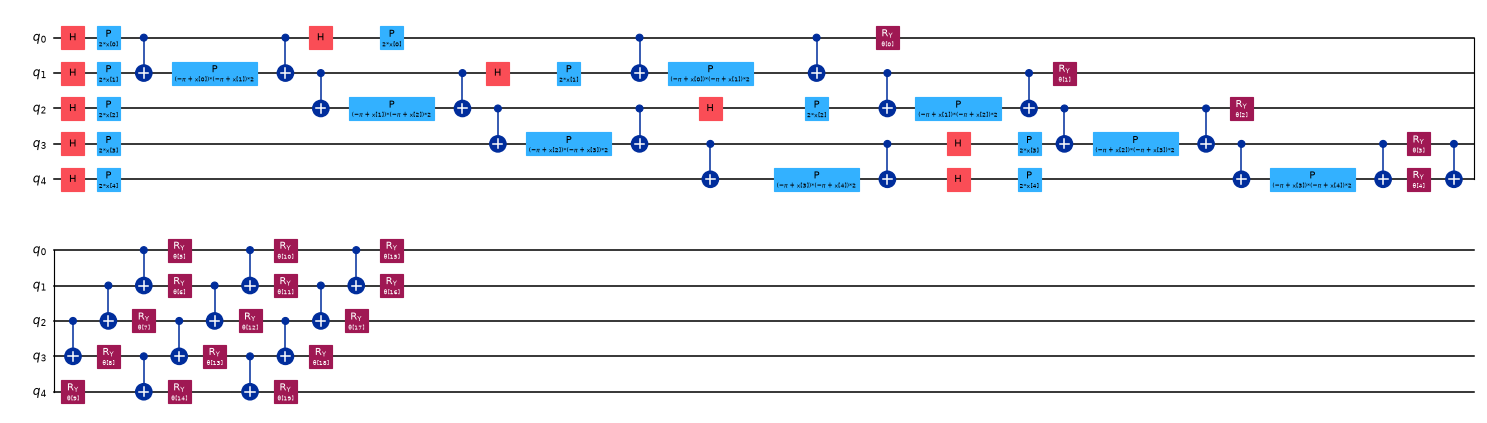

Architecture 3, QSVM kernel circuit (feature map of a, then inverse feature map of b): qubits = 5 | depth = 44 (in H/P/CX/RY gates: 44) | gates = {'p': 36, 'cx': 32, 'h': 20} | trainable parameters = 0 | data parameters = 5


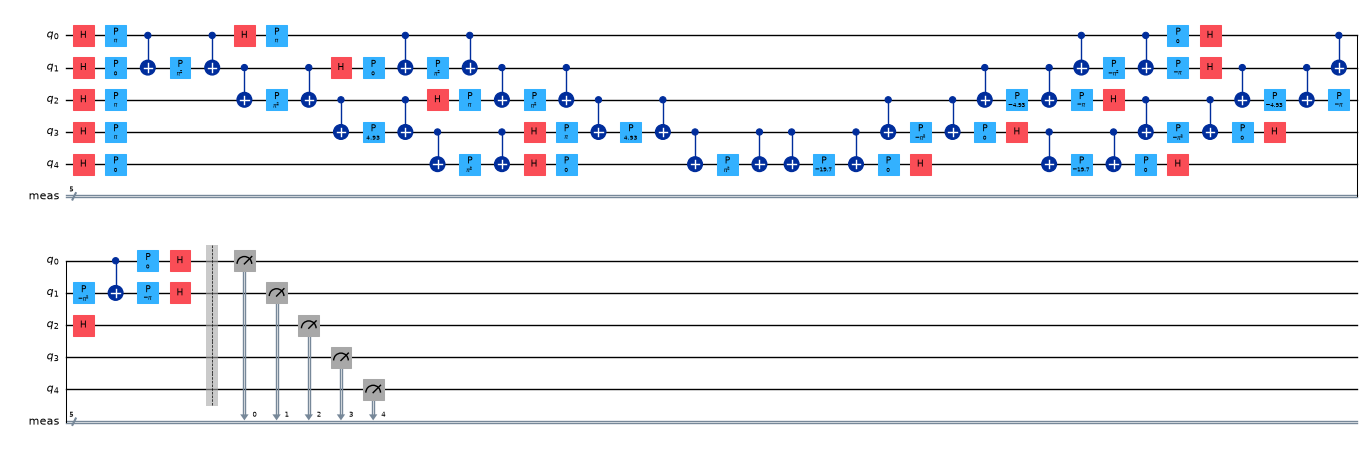

The kernel entry is the probability of measuring the all-zero bit string (shown here for the apps a = 10110 and b = 01100).


In [9]:
# ----- Architecture 2: the same family on 5 qubits (IBM 5-qubit protocol)
b2 = describe(f"Architecture 2, VQC with {HW_QUBITS} qubits", kit5.qc, kit5.an.num_parameters, kit5.fm.num_parameters)
fig = b2.draw("mpl", fold=40, scale=0.55); display(fig); plt.close(fig)

# ----- Architecture 3: compute-uncompute circuit for one QSVM kernel entry K(a, b) = |<0|U(b)^dagger U(a)|0>|^2
ka, kb = np.array([1, 0, 1, 1, 0]) * 1.0, np.array([0, 1, 1, 0, 0]) * 1.0
qk = QuantumCircuit(HW_QUBITS)
qk.compose(kit5.fm.assign_parameters(dict(zip(kit5.fm.parameters, ka * np.pi / 2))), inplace=True)
qk.compose(kit5.fm.assign_parameters(dict(zip(kit5.fm.parameters, kb * np.pi / 2))).inverse(), inplace=True)
qk.measure_all()
b3 = describe("Architecture 3, QSVM kernel circuit (feature map of a, then inverse feature map of b)", qk.remove_final_measurements(inplace=False), 0, kit5.fm.num_parameters)
fig = transpile(qk, basis_gates=["h", "p", "cx"], optimization_level=0).draw("mpl", fold=40, scale=0.5); display(fig); plt.close(fig)
print("The kernel entry is the probability of measuring the all-zero bit string (shown here for the apps a = 10110 and b = 01100).")

In [10]:
# ----- Equivalence checks: the fast exact simulator == Qiskit's Statevector == the stock VQC network
def stock_vqc_network(k_):
    stock = VQC(feature_map=k_.fm, ansatz=k_.an, optimizer=COBYLA(maxiter=1),
                sampler=StatevectorSampler(default_shots=2 ** 17, seed=SEED))
    return stock, stock.neural_network

chk = np.random.default_rng(SEED)
for k_, Q_ in [(kit, FastQNN), (kit5, FastQNN5)]:
    stock, stock_qnn = stock_vqc_network(k_)
    fast_qnn = Q_(sampler=StatevectorSampler(), circuit=stock.circuit, input_params=k_.fm.parameters, weight_params=k_.an.parameters,
                  interpret=stock.interpret, output_shape=2, input_gradients=False)
    Xc = chk.integers(0, 2, (3, k_.n)).astype(float) * ANGLE_VQC
    wc = chk.uniform(0, 2 * np.pi, k_.an.num_parameters)
    a = fast_qnn.forward(Xc, wc)                                        # fast exact simulator
    b = stock_qnn.forward(Xc, wc)                                       # stock Qiskit network, 2^17 shots
    ex = np.array([Statevector(k_.qc.assign_parameters({**dict(zip(k_.fm.parameters, x)), **dict(zip(k_.an.parameters, wc))})).probabilities([0]) for x in Xc])
    assert np.allclose(a, ex, atol=1e-10), (a, ex)
    assert np.allclose(a, b, atol=0.02), (a, b)
    print(f"{k_.n} qubits: fast simulator == Statevector (max |diff| {np.abs(a - ex).max():.1e}) and == stock VQC network with 131,072 shots (max |diff| {np.abs(a - b).max():.4f}, shot noise)")

# kernel: Gram matrix from stored feature-map states == FidelityStatevectorKernel; QSVC == SVC(kernel="precomputed")
Xk = np.random.default_rng(SEED).integers(0, 2, (14, HW_QUBITS)).astype(float) * ANGLE_VQC
yk = np.random.default_rng(SEED).integers(0, 2, 14)
ker = FidelityStatevectorKernel(feature_map=kit5.fm)
Kq = ker.evaluate(Xk[:8], Xk[8:]); Kf = kit5.gram(Xk[:8], Xk[8:])
assert np.allclose(Kq, Kf, atol=1e-9), np.abs(Kq - Kf).max()
qsvc = QSVC(quantum_kernel=ker, C=1.0).fit(Xk[:8], yk[:8]); sv = SVC(kernel="precomputed", C=1.0).fit(kit5.gram(Xk[:8]), yk[:8])
assert (qsvc.predict(Xk[8:]) == sv.predict(Kf.T)).all()
print("Kernel check passed: Gram matrix == FidelityStatevectorKernel (max |diff| %.1e); QSVC predictions == SVC(precomputed)." % np.abs(Kq - Kf).max())

8 qubits: fast simulator == Statevector (max |diff| 3.0e-15) and == stock VQC network with 131,072 shots (max |diff| 0.0005, shot noise)


5 qubits: fast simulator == Statevector (max |diff| 2.0e-15) and == stock VQC network with 131,072 shots (max |diff| 0.0014, shot noise)


Kernel check passed: Gram matrix == FidelityStatevectorKernel (max |diff| 3.6e-15); QSVC predictions == SVC(precomputed).


**Why the angle scale matters for binary data (the `# CHOICE:` on angles).** The paper says the data are mapped to `(0, 2 pi]`. Drebin features are 0 or 1, so a min-max scaling to `(0, 2 pi]` would send a "1" to `2 pi`, which is the identity rotation. With the scale `pi` the single-qubit phase is also `2 pi` and the two-qubit phase `(pi - x_i)(pi - x_j)` vanishes whenever one of the two features is 1: a present feature would be erased from the circuit. The VQC therefore uses the angles `0` and `pi/2`; the QSVM scale is chosen on validation data in section 5.

## 3. The models, written once

* `fit_vqc` is the real Qiskit `VQC` (ZZ map, RealAmplitudes, COBYLA, cross-entropy). Only its forward pass is replaced by the verified exact simulator, so the training loop, the loss and the optimiser are Qiskit's.
* `qsvm_predict` computes the fidelity kernel between all training and test points and passes it to a standard SVM (`C = 1`), exactly what `QSVC` does.
* `metrics` returns accuracy, precision, recall and F1 of the malware class (positive class) and the confusion matrix counts.

In [11]:
def metrics(y, p):
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    return dict(acc=accuracy_score(y, p), prec=precision_score(y, p, zero_division=0), rec=recall_score(y, p, zero_division=0),
                f1=f1_score(y, p, zero_division=0), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def fit_vqc(k_, Q_, A_tr, y_tr, A_evals, maxiter, seed):
    """Train Qiskit's VQC (forward pass = verified exact simulator); returns predictions for every array in A_evals."""
    if len(np.unique(y_tr)) < 2:                       # degenerate tiny training set: predict the only class
        return [np.full(len(a), y_tr[0]) for a in A_evals], 0.0, [], None
    algorithm_globals.random_seed = seed
    losses = []
    vqc = VQC(feature_map=k_.fm, ansatz=k_.an, optimizer=COBYLA(maxiter=maxiter), callback=lambda w, f: losses.append(float(f)),
              sampler=StatevectorSampler(default_shots=1024, seed=seed))
    vqc._neural_network = Q_(sampler=StatevectorSampler(), circuit=vqc.circuit, input_params=k_.fm.parameters,
                             weight_params=k_.an.parameters, interpret=vqc.interpret, output_shape=2, input_gradients=False)
    t0 = time.time(); vqc.fit(A_tr, y_tr); t_fit = time.time() - t0
    vqc._fit_weights = np.asarray(vqc.weights).copy()
    return [np.asarray(vqc.predict(a)).astype(int) for a in A_evals], t_fit, losses, vqc

def qsvm_predict(k_, A_tr, y_tr, A_te, C=1.0):
    if len(np.unique(y_tr)) < 2:
        return np.full(len(A_te), y_tr[0])
    sv = SVC(kernel="precomputed", C=C).fit(k_.gram(A_tr), y_tr)
    return sv.predict(k_.gram(A_te, A_tr))

def mean_ci(v, level=0.95):
    v = np.asarray(v, float); n = len(v)
    sd = v.std(ddof=1) if n > 1 else 0.0
    return v.mean(), sd, (stats.t.ppf(0.5 + level / 2, n - 1) * sd / np.sqrt(n) if n > 1 else 0.0)

def verdict(paper, ours, tol=2.0):
    d = ours - paper
    if abs(d) <= tol: return f"reproduced ({d:+.1f} pts)"
    return f"not reached ({d:+.1f} pts)" if d < 0 else f"exceeded ({d:+.1f} pts)"
print("helpers ready")

helpers ready


## 4. Experiment 1: VQC with XGBoost versus decision-tree features (paper Section 5, first claim)

For every seed: draw `N_TOTAL` random apps from the whole dataset (the natural 63 % benign / 37 % malware mix, as in the paper's "10,000 samples"), split them 50/50 (stratified), let each selector choose `N_QUBITS` features **from the training half**, train the VQC on the training half and report the accuracy on the test half. Random forest, RBF-SVM and XGBoost are trained on exactly the same selected columns; a random forest on all 215 features and the majority-class rule are given as references. The majority-class rule matters: always answering "benign" is already about 63 % accurate.

In [12]:
exp1_rows, exp1_cols, loss_store, vqc_store = [], {}, {}, {}
PAPER_K = 20
t_exp1 = time.time()
for si in range(N_SEEDS):
    seed = SEED + si
    r_ = np.random.default_rng(seed)
    idx = r_.choice(len(X_all), N_TOTAL, replace=False)
    Xs, ys = X_all.iloc[idx], y_all[idx]
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=TEST_SIZE, stratify=ys, random_state=seed)
    exp1_rows.append(dict(seed=seed, variant="(all)", model="majority class", fit_s=0.0, **metrics(yte, np.zeros_like(yte))))
    rf_all = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr, ytr)
    exp1_rows.append(dict(seed=seed, variant="(all)", model="RandomForest, all 215 features", fit_s=0.0, **metrics(yte, rf_all.predict(Xte))))
    for v in VARIANTS:
        cols, _ = select_features(v, Xtr, ytr, N_QUBITS, seed)
        exp1_cols[(seed, v)] = cols
        Atr, Ate = Xtr[cols].values * ANGLE_VQC, Xte[cols].values * ANGLE_VQC
        (p,), t_fit, losses, vqc = fit_vqc(kit, FastQNN, Atr, ytr, [Ate], MAXITER, seed)
        acc_vqc = accuracy_score(yte, p)
        exp1_rows.append(dict(seed=seed, variant=v, model="VQC", fit_s=t_fit, **metrics(yte, p)))
        loss_store[(seed, v)] = losses
        # classical baselines on the identical selected columns
        rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr[cols], ytr)
        sv = SVC(kernel="rbf", C=1.0).fit(Xtr[cols], ytr)
        xg = XGBClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr[cols], ytr)
        exp1_rows.append(dict(seed=seed, variant=v, model="RandomForest", fit_s=0.0, **metrics(yte, rf.predict(Xte[cols]))))
        exp1_rows.append(dict(seed=seed, variant=v, model="SVC rbf", fit_s=0.0, **metrics(yte, sv.predict(Xte[cols]))))
        exp1_rows.append(dict(seed=seed, variant=v, model="XGBoost", fit_s=0.0, **metrics(yte, xg.predict(Xte[cols]))))
        # the paper's own feature count (20) for the classical models only, since 20 qubits are not simulated here
        if v in ("xgboost", "decision_tree"):
            c20, _ = select_features(v, Xtr, ytr, PAPER_K, seed)
            rf20 = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr[c20], ytr)
            sv20 = SVC(kernel="rbf", C=1.0).fit(Xtr[c20], ytr)
            exp1_rows.append(dict(seed=seed, variant=v, model="RandomForest, top-20", fit_s=0.0, **metrics(yte, rf20.predict(Xte[c20]))))
            exp1_rows.append(dict(seed=seed, variant=v, model="SVC rbf, top-20", fit_s=0.0, **metrics(yte, sv20.predict(Xte[c20]))))
        print(f"seed {seed} | {v:14s} | VQC acc {acc_vqc:.4f} | RF {rf.score(Xte[cols], yte):.4f} | SVC {sv.score(Xte[cols], yte):.4f} | fit {t_fit:.0f}s")
exp1 = pd.DataFrame(exp1_rows)
print("Experiment 1 wall time: %.1f min" % ((time.time() - t_exp1) / 60))

seed 42 | xgboost        | VQC acc 0.8364 | RF 0.9078 | SVC 0.9070 | fit 7s


seed 42 | decision_tree  | VQC acc 0.7454 | RF 0.9288 | SVC 0.9288 | fit 17s


seed 42 | random_forest  | VQC acc 0.7382 | RF 0.9156 | SVC 0.9172 | fit 12s


seed 42 | f_classif      | VQC acc 0.7556 | RF 0.8186 | SVC 0.8186 | fit 7s


seed 42 | correlation    | VQC acc 0.7556 | RF 0.8186 | SVC 0.8186 | fit 15s


...

seed 44 | random_forest  | VQC acc 0.7770 | RF 0.9024 | SVC 0.9030 | fit 16s


seed 44 | f_classif      | VQC acc 0.7206 | RF 0.8170 | SVC 0.8174 | fit 46s


seed 44 | correlation    | VQC acc 0.7206 | RF 0.8170 | SVC 0.8174 | fit 43s


seed 44 | first          | VQC acc 0.7542 | RF 0.8170 | SVC 0.8174 | fit 39s


seed 44 | random         | VQC acc 0.6586 | RF 0.8128 | SVC 0.8136 | fit 62s
Experiment 1 wall time: 20.3 min


,acc,acc_std,prec,rec,f1,fit_s,acc RandomForest,acc SVC rbf,acc XGBoost
variant,,,,,,,,,
xgboost,0.8044,0.0355,0.7946,0.6599,0.7060,7.2135,0.9100,0.9093,0.9096
decision_tree,0.8001,0.0475,0.6823,0.8782,0.7665,20.4778,0.9275,0.9269,0.9279
random_forest,0.7595,0.0197,0.6997,0.6837,0.6603,10.3965,0.9120,0.9127,0.9127
f_classif,0.7102,0.0514,0.5686,0.9319,0.7054,19.9344,0.8167,0.8166,0.8168
correlation,0.7102,0.0514,0.5686,0.9319,0.7054,22.6352,0.8167,0.8166,0.8168
first,0.7619,0.0124,0.7215,0.6525,0.6587,16.5095,0.8167,0.8166,0.8168
random,0.6771,0.0831,0.5425,0.7491,0.6268,24.7683,0.7562,0.7565,0.7566


References (all features, top-20 classical, majority class):


acc  acc_std
variant       model                                          
(all)         RandomForest, all 215 features  0.9823   0.0013
              majority class                  0.6299   0.0015
decision_tree RandomForest, top-20            0.9595   0.0046
              SVC rbf, top-20                 0.9537   0.0025
xgboost       RandomForest, top-20            0.9527   0.0039
              SVC rbf, top-20                 0.9491   0.0006

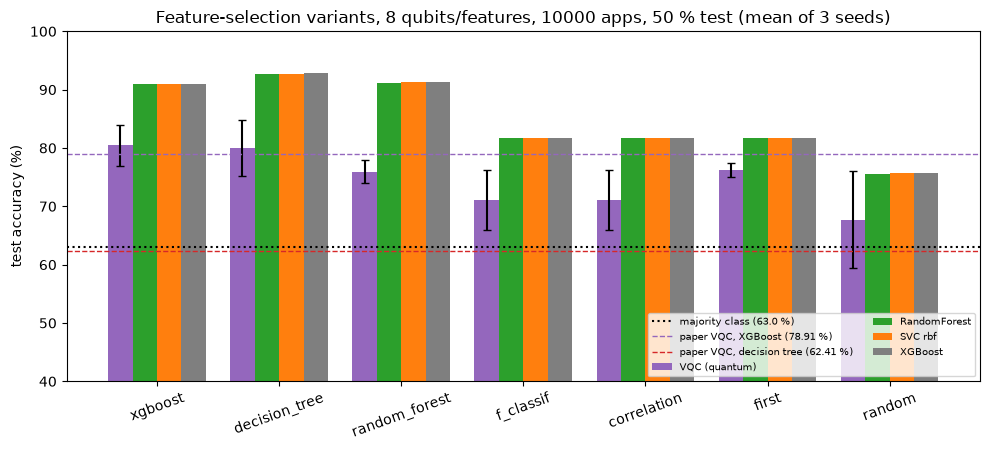

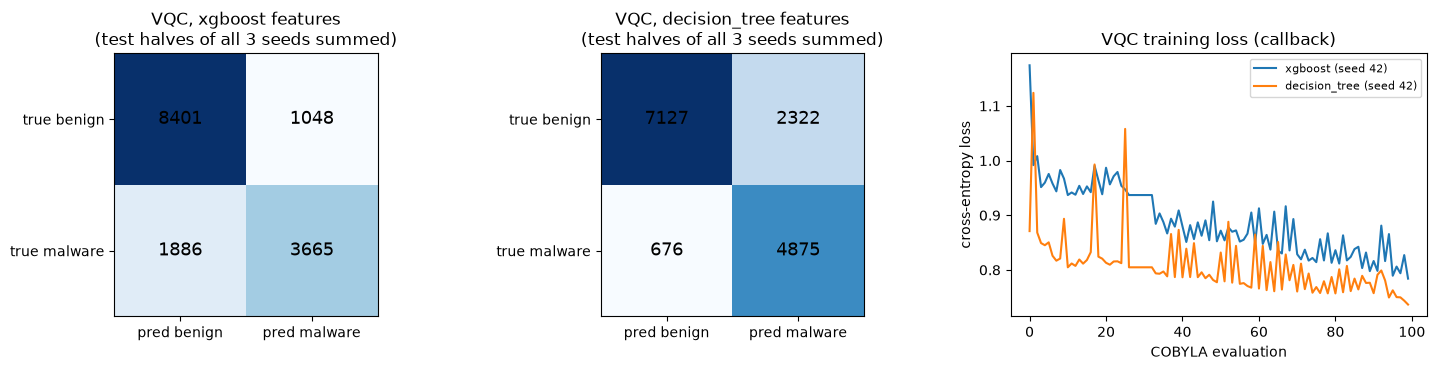

In [13]:
agg = exp1.groupby(["variant", "model"]).agg(acc=("acc", "mean"), acc_std=("acc", "std"), prec=("prec", "mean"), rec=("rec", "mean"),
                                             f1=("f1", "mean"), fit_s=("fit_s", "mean")).reset_index()
vqc_tab = agg[agg.model == "VQC"].set_index("variant").reindex(VARIANTS)
base_tab = agg[agg.model.isin(["RandomForest", "SVC rbf", "XGBoost"])].pivot(index="variant", columns="model", values="acc").reindex(VARIANTS)
summary1 = vqc_tab[["acc", "acc_std", "prec", "rec", "f1", "fit_s"]].join(base_tab.add_prefix("acc "))
display(summary1.round(4))
extra = agg[~agg.model.isin(["VQC", "RandomForest", "SVC rbf", "XGBoost"])].set_index(["variant", "model"])[["acc", "acc_std"]]
print("References (all features, top-20 classical, majority class):"); display(extra.round(4))

fig, ax = plt.subplots(figsize=(10, 4.6))
xs = np.arange(len(VARIANTS)); w = 0.2
ax.bar(xs - 1.5 * w, vqc_tab["acc"] * 100, w, yerr=vqc_tab["acc_std"].fillna(0) * 100, capsize=3, label="VQC (quantum)", color="tab:purple")
for off, mname, colr in [(-0.5, "RandomForest", "tab:green"), (0.5, "SVC rbf", "tab:orange"), (1.5, "XGBoost", "tab:gray")]:
    ax.bar(xs + off * w, base_tab[mname] * 100, w, label=mname, color=colr)
maj = exp1[exp1.model == "majority class"].acc.mean() * 100
ax.axhline(maj, color="k", ls=":", label=f"majority class ({maj:.1f} %)")
ax.axhline(78.91, color="tab:purple", ls="--", lw=1, label="paper VQC, XGBoost (78.91 %)")
ax.axhline(62.41, color="tab:red", ls="--", lw=1, label="paper VQC, decision tree (62.41 %)")
ax.set_xticks(xs); ax.set_xticklabels(VARIANTS, rotation=20); ax.set_ylabel("test accuracy (%)"); ax.set_ylim(40, 100)
ax.set_title(f"Feature-selection variants, {N_QUBITS} qubits/features, {N_TOTAL} apps, 50 % test (mean of {N_SEEDS} seeds)")
ax.legend(fontsize=7, ncol=2, loc="lower right"); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, v in zip(axes[:2], ["xgboost", "decision_tree"]):
    cm = exp1[(exp1.variant == v) & (exp1.model == "VQC")][["tn", "fp", "fn", "tp"]].sum()
    M = np.array([[cm.tn, cm.fp], [cm.fn, cm.tp]])
    ax.imshow(M, cmap="Blues")
    for i in range(2):
        for j in range(2): ax.text(j, i, int(M[i, j]), ha="center", va="center", color="k", fontsize=13)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred benign", "pred malware"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true benign", "true malware"])
    ax.set_title(f"VQC, {v} features\n(test halves of all {N_SEEDS} seeds summed)")
for sd, v_ in [(SEED, "xgboost"), (SEED, "decision_tree")]:
    axes[2].plot(loss_store[(sd, v_)], label=f"{v_} (seed {sd})")
axes[2].set_xlabel("COBYLA evaluation"); axes[2].set_ylabel("cross-entropy loss"); axes[2].set_title("VQC training loss (callback)"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

k= 4 xgboost        VQC 0.8486 RF 0.8712 (11s)


k= 4 decision_tree  VQC 0.8674 RF 0.9076 (15s)


k= 6 xgboost        VQC 0.8460 RF 0.8834 (13s)


k= 6 decision_tree  VQC 0.8312 RF 0.9216 (12s)


k= 8 xgboost        VQC 0.8364 RF 0.9078 (13s)


k= 8 decision_tree  VQC 0.7454 RF 0.9288 (21s)


k=10 xgboost        VQC 0.7494 RF 0.9132 (273s)


k=10 decision_tree  VQC 0.6440 RF 0.9318 (738s)


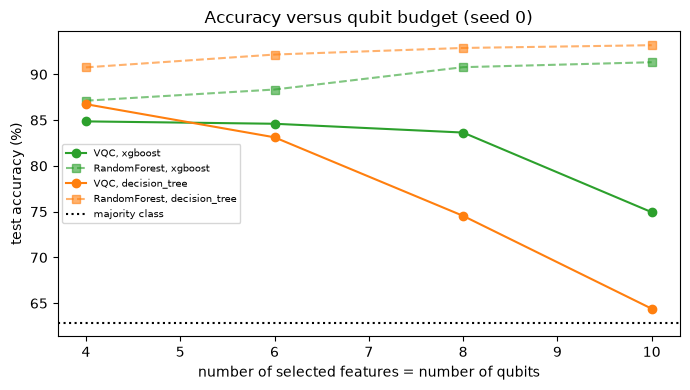

Sweep wall time: 20.8 min


In [14]:
# How many qubits/features are needed? (seed 0 only; selectors of the paper; classical models on the same columns for reference)
seed = SEED
r_ = np.random.default_rng(seed); idx = r_.choice(len(X_all), N_TOTAL, replace=False)
Xs, ys = X_all.iloc[idx], y_all[idx]
Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=TEST_SIZE, stratify=ys, random_state=seed)
sweep_rows = []
t_sw = time.time()
for kq in QUBIT_SWEEP:
    kk, QQ = (kit, FastQNN) if kq == N_QUBITS else (QuantumModelKit(kq), None)
    if QQ is None: QQ = make_fast_qnn(kk)
    for v in ["xgboost", "decision_tree"]:
        cols, _ = select_features(v, Xtr, ytr, kq, seed)
        (p,), t_fit, _, _ = fit_vqc(kk, QQ, Xtr[cols].values * ANGLE_VQC, ytr, [Xte[cols].values * ANGLE_VQC], MAXITER, seed)
        rf = RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1).fit(Xtr[cols], ytr)
        sweep_rows.append(dict(qubits=kq, selector=v, vqc_acc=accuracy_score(yte, p), rf_acc=rf.score(Xte[cols], yte), fit_s=t_fit))
        print(f"k={kq:2d} {v:14s} VQC {sweep_rows[-1]['vqc_acc']:.4f} RF {sweep_rows[-1]['rf_acc']:.4f} ({t_fit:.0f}s)")
sweep = pd.DataFrame(sweep_rows)
fig, ax = plt.subplots(figsize=(7, 4))
for v, c in [("xgboost", "tab:green"), ("decision_tree", "tab:orange")]:
    d_ = sweep[sweep.selector == v]
    ax.plot(d_.qubits, d_.vqc_acc * 100, "o-", color=c, label=f"VQC, {v}")
    ax.plot(d_.qubits, d_.rf_acc * 100, "s--", color=c, alpha=0.6, label=f"RandomForest, {v}")
ax.axhline(100 * (1 - yte.mean()), color="k", ls=":", label="majority class")
ax.set_xlabel("number of selected features = number of qubits"); ax.set_ylabel("test accuracy (%)"); ax.set_title("Accuracy versus qubit budget (seed 0)")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print("Sweep wall time: %.1f min" % ((time.time() - t_sw) / 60))

## 5. Experiment 2: QSVM on 20 random apps, ten runs (paper Section 5, second claim)

The IBM machines of the paper have 5 qubits, so only 5 features and only 20 apps per run (10 for training, 10 for testing) could be used; the paper repeats this ten times and reports the mean accuracy with a 95 % confidence interval (74 % +- 11.35 for XGBoost-selected features). We reproduce the protocol with an exact 5-qubit kernel simulator:

* the 5 features are chosen by the selector on the **development part** (70 % of the data), the 20 apps of every run are drawn from the **hold-out part**, so the selector never sees the apps it is tested on (a stricter reading than the paper, which does not say how the selection was done);
* the kernel scale (the angle given to a present feature) is the only QSVM hyper-parameter; it is chosen on a validation split **inside the development part**;
* the interval is a Student-t interval over the ten runs.

In [15]:
# Choose the kernel scale on a validation split inside the development part (5 XGBoost features, 600 apps)
r_ = np.random.default_rng(SEED)
sub = r_.choice(len(Xdev), 600, replace=False)
Xa, Xb, ya, yb = train_test_split(Xdev.iloc[sub], ydev[sub], test_size=0.4, stratify=ydev[sub], random_state=SEED)
cols_val, _ = select_features("xgboost", Xa, ya, HW_QUBITS, SEED)
grid = {"pi/8": np.pi / 8, "pi/4": np.pi / 4, "pi/2": np.pi / 2, "3pi/4": 3 * np.pi / 4, "pi": np.pi}
val_rows = []
for nm, sc in grid.items():
    p = qsvm_predict(kit5, Xa[cols_val].values * sc, ya, Xb[cols_val].values * sc)
    val_rows.append(dict(scale=nm, value=sc, validation_acc=accuracy_score(yb, p)))
val_tab = pd.DataFrame(val_rows); display(val_tab.round(4))
best_acc = val_tab.validation_acc.max()
tied = val_tab[val_tab.validation_acc >= best_acc - 1e-12]
ANGLE_QSVM = float(tied.iloc[(tied.value - np.pi / 2).abs().argsort().iloc[0]]["value"])     # CHOICE: ties are broken towards pi/2
print("Chosen QSVM angle scale: %.4f rad (validation accuracy %.4f; %d of %d scales tie)" % (ANGLE_QSVM, best_acc, len(tied), len(val_tab)))
if len(tied) > 1:
    print("Several scales give the same validation accuracy: with 5 binary features there are only 32 distinct apps, and with 360 training apps"
          " the SVM mostly acts as a lookup table of the majority label of each pattern, whatever the kernel scale.")

# Selectors for the 5-qubit protocol, fitted on the whole development part
cols5 = {v: select_features(v, Xdev, ydev, HW_QUBITS, SEED)[0] for v in ["xgboost", "decision_tree"]}
print({k_: v_ for k_, v_ in cols5.items()})

,scale,value,validation_acc
0,pi/8,0.3927,0.7958
1,pi/4,0.7854,0.7958
2,pi/2,1.5708,0.7958
3,3pi/4,2.3562,0.7958
4,pi,3.1416,0.7958


Chosen QSVM angle scale: 1.5708 rad (validation accuracy 0.7958; 5 of 5 scales tie)
Several scales give the same validation accuracy: with 5 binary features there are only 32 distinct apps, and with 360 training apps the SVM mostly acts as a lookup table of the majority label of each pattern, whatever the kernel scale.


{'xgboost': ['transact', 'onServiceConnected', 'READ_PHONE_STATE', 'DELETE_CACHE_FILES', 'SEND_SMS'], 'decision_tree': ['transact', 'READ_PHONE_STATE', 'SEND_SMS', 'TelephonyManager.getDeviceId', 'Ljava.lang.Class.getCanonicalName']}


mean_acc     std  ci95_halfwidth  runs
selector      model                                                 
decision_tree QSVM                0.75  0.1650          0.1180    10
              RandomForest        0.85  0.0972          0.0695    10
              SVC rbf             0.84  0.1174          0.0840    10
              VQC                 0.78  0.1398          0.1000    10
              majority class      0.62  0.0632          0.0452    10
xgboost       QSVM                0.77  0.1337          0.0957    10
              RandomForest        0.83  0.1636          0.1171    10
              SVC rbf             0.85  0.1179          0.0843    10
              VQC                 0.70  0.1886          0.1349    10
              majority class      0.62  0.0632          0.0452    10

Malware apps per run (train/test), first run: 4 / 3


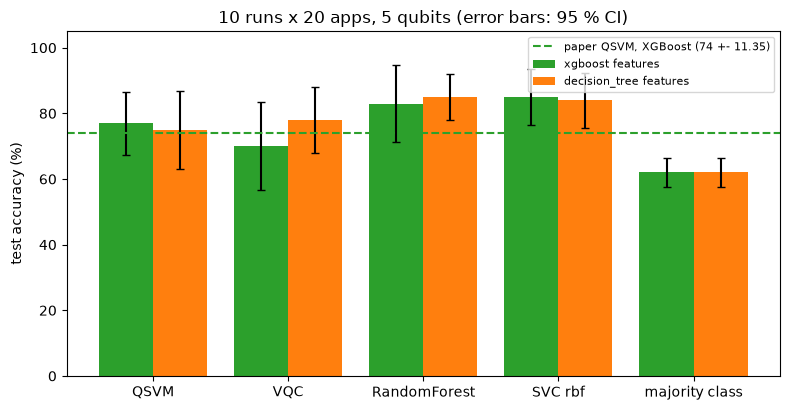

In [16]:
def draw_runs(n_runs, n_samples, seed0):
    """The (train, test) apps of every run: n_samples random hold-out apps, 50 % split."""
    out = []
    for run in range(n_runs):
        s = seed0 + run
        idx = np.random.default_rng(s).choice(len(Xhold), n_samples, replace=False)
        ys = yhold[idx]
        strat = ys if np.bincount(ys, minlength=2).min() >= 2 else None
        itr, ite = train_test_split(idx, test_size=0.5, stratify=strat, random_state=s)
        out.append((s, itr, ite))
    return out

hw_runs = draw_runs(HW_RUNS, HW_SAMPLES, SEED)
exp2_rows = []
for s, itr, ite in hw_runs:
    ytr, yte = yhold[itr], yhold[ite]
    for v in ["xgboost", "decision_tree"]:
        cols = cols5[v]
        Atr, Ate = Xhold.iloc[itr][cols].values, Xhold.iloc[ite][cols].values
        p_q = qsvm_predict(kit5, Atr * ANGLE_QSVM, ytr, Ate * ANGLE_QSVM)
        (p_v,), _, _, _ = fit_vqc(kit5, FastQNN5, Atr * ANGLE_VQC, ytr, [Ate * ANGLE_VQC], MAXITER, s)
        rf = RandomForestClassifier(n_estimators=100, random_state=s, n_jobs=1).fit(Atr, ytr) if len(np.unique(ytr)) > 1 else None
        sv = SVC(kernel="rbf").fit(Atr, ytr) if len(np.unique(ytr)) > 1 else None
        p_rf = rf.predict(Ate) if rf is not None else np.full(len(yte), ytr[0])
        p_sv = sv.predict(Ate) if sv is not None else np.full(len(yte), ytr[0])
        for mdl, p in [("QSVM", p_q), ("VQC", p_v), ("RandomForest", p_rf), ("SVC rbf", p_sv), ("majority class", np.zeros_like(yte))]:
            exp2_rows.append(dict(run=s, selector=v, model=mdl, acc=accuracy_score(yte, p), n_malware_train=int(ytr.sum()), n_malware_test=int(yte.sum())))
exp2 = pd.DataFrame(exp2_rows)
rows = []
for (v, m), d in exp2.groupby(["selector", "model"]):
    mu, sd, ci = mean_ci(d.acc.values)
    rows.append(dict(selector=v, model=m, mean_acc=mu, std=sd, ci95_halfwidth=ci, runs=len(d)))
tab2 = pd.DataFrame(rows).set_index(["selector", "model"]); display(tab2.round(4))
print("Malware apps per run (train/test), first run:", exp2[exp2.run == SEED].n_malware_train.iloc[0], "/", exp2[exp2.run == SEED].n_malware_test.iloc[0])

fig, ax = plt.subplots(figsize=(8, 4.2))
order = ["QSVM", "VQC", "RandomForest", "SVC rbf", "majority class"]
for off, v, c in [(-0.2, "xgboost", "tab:green"), (0.2, "decision_tree", "tab:orange")]:
    d_ = tab2.loc[v].reindex(order)
    ax.bar(np.arange(len(order)) + off, d_.mean_acc * 100, 0.4, yerr=d_.ci95_halfwidth * 100, capsize=3, label=f"{v} features", color=c)
ax.axhline(74, color="tab:green", ls="--", label="paper QSVM, XGBoost (74 +- 11.35)")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_ylabel("test accuracy (%)"); ax.set_ylim(0, 105)
ax.set_title(f"{HW_RUNS} runs x {HW_SAMPLES} apps, {HW_QUBITS} qubits (error bars: 95 % CI)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Experiment 3: does re-balancing the training data help? (paper Section 5, bullets)

The paper reports that over-sampling (SMOTE, ADASYN), under-sampling (K-means; removing samples that disagree with their neighbourhood) and a combination raise the QSVM accuracy from 74 % to 77-84 %. It does not say how many samples or which model. We test the five ideas with the QSVM of experiment 2 (XGBoost features, 5 qubits) at two scales: the paper's 20 apps per run, and a larger `RS_SAMPLES` apps per run in which the minority class has enough members for the neighbour-based methods. Resampling touches the **training half only**; the test half keeps the natural class mix.

| Paper idea | `imbalanced-learn` object | Note |
|---|---|---|
| SMOTE | `SMOTE` | new minority points are interpolated between neighbours; binary features become values in [0, 1] |
| ADASYN | `ADASYN` | like SMOTE, more points near the decision border |
| removing samples with K-means | `ClusterCentroids` | the majority class is replaced by K-means centroids |
| removing samples that disagree with their neighbourhood | `EditedNearestNeighbours` | Wilson editing |
| over- plus under-sampling | `SMOTEENN` and `SMOTETomek` | SMOTE followed by a cleaning step; the paper does not name the cleaner |

If a resampler cannot run (fewer than two minority samples, or no neighbours), the run falls back to the un-resampled training set and is counted in `fallbacks`.

mean_acc     std  ci95_halfwidth  fallbacks  runs  mean_train_size
scale                   method                                                                                   
paper scale (20 apps)   none                      0.770  0.1337          0.0957          0    10             10.0
                        SMOTE                     0.740  0.1430          0.1023          0    10             11.6
                        ADASYN                    0.730  0.1829          0.1308          2    10             11.1
                        KMeans under-sampling     0.720  0.1932          0.1382          0    10              8.4
                        ENN under-sampling        0.700  0.1333          0.0954          3    10              8.8
                        SMOTE+ENN                 0.700  0.1333          0.0954          4    10              9.4
                        SMOTE+Tomek               0.750  0.1269          0.0908          0    10             11.4
larger scale (200 apps) none                      0.891  0.0251          0.0180          0    10            100.0
                        SMOTE                     0.881  0.0341          0.0244          0    10            129.0
                        ADASYN                    0.884  0.0327          0.0234          0    10            129.4
                        KMeans under-sampling     0.767  0.1297          0.0928          0    10             71.0
                        ENN under-sampling        0.804  0.1140          0.0816          0    10             85.1
                        SMOTE+ENN                 0.753  0.0757          0.0542          0    10             83.0
                        SMOTE+Tomek               0.881  0.0341          0.0244          0    10            129.0

Experiment 3 wall time: 0.8 min


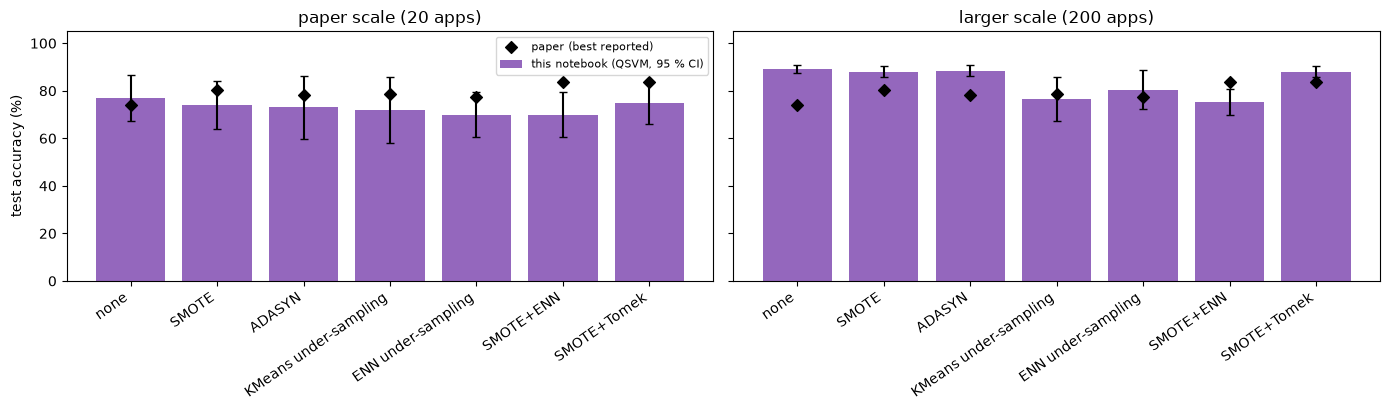

In [17]:
def make_resampler(name, y_tr, seed):
    n_min = int(np.bincount(y_tr, minlength=2).min())
    if name == "none": return None
    if n_min < 2: raise ValueError("fewer than two minority samples")
    kn = max(1, min(5, n_min - 1))
    if name == "SMOTE": return SMOTE(random_state=seed, k_neighbors=kn)
    if name == "ADASYN": return ADASYN(random_state=seed, n_neighbors=kn)
    if name == "KMeans under-sampling": return ClusterCentroids(random_state=seed)
    if name == "ENN under-sampling": return EditedNearestNeighbours(n_neighbors=min(3, len(y_tr) - 1))
    if name == "SMOTE+ENN": return SMOTEENN(random_state=seed, smote=SMOTE(random_state=seed, k_neighbors=kn))
    if name == "SMOTE+Tomek": return SMOTETomek(random_state=seed, smote=SMOTE(random_state=seed, k_neighbors=kn))
    raise ValueError(name)

RS_METHODS = ["none", "SMOTE", "ADASYN", "KMeans under-sampling", "ENN under-sampling", "SMOTE+ENN", "SMOTE+Tomek"]

def run_resampling(runs, scale_name):
    rows = []
    for s, itr, ite in runs:
        ytr, yte = yhold[itr], yhold[ite]
        cols = cols5["xgboost"]
        Atr01, Ate01 = Xhold.iloc[itr][cols].values, Xhold.iloc[ite][cols].values
        for name in RS_METHODS:
            fb = 0
            try:
                rs = make_resampler(name, ytr, s)
                if rs is None: A, yy = Atr01, ytr
                else:
                    A, yy = rs.fit_resample(Atr01, ytr)
                    if len(np.unique(yy)) < 2 or len(yy) < 2: raise ValueError("resampled set has one class")
            except Exception as e:
                A, yy, fb = Atr01, ytr, 1
            p = qsvm_predict(kit5, A * ANGLE_QSVM, yy, Ate01 * ANGLE_QSVM)
            rows.append(dict(scale=scale_name, run=s, method=name, acc=accuracy_score(yte, p), fallback=fb, n_train_after=len(yy)))
    return pd.DataFrame(rows)

t_rs = time.time()
rs_small = run_resampling(hw_runs, f"paper scale ({HW_SAMPLES} apps)")
rs_big = run_resampling(draw_runs(RS_RUNS, RS_SAMPLES, 1000 + SEED), f"larger scale ({RS_SAMPLES} apps)")
rs_all = pd.concat([rs_small, rs_big])
rows = []
for (sc, m), d in rs_all.groupby(["scale", "method"], sort=False):
    mu, sd, ci = mean_ci(d.acc.values)
    rows.append(dict(scale=sc, method=m, mean_acc=mu, std=sd, ci95_halfwidth=ci, fallbacks=int(d.fallback.sum()), runs=len(d), mean_train_size=d.n_train_after.mean()))
tab3 = pd.DataFrame(rows)
display(tab3.set_index(["scale", "method"]).round(4))
print("Experiment 3 wall time: %.1f min" % ((time.time() - t_rs) / 60))

PAPER_RS = {"none": 74.0, "SMOTE": 80.15, "ADASYN": 78.06, "KMeans under-sampling": 78.62, "ENN under-sampling": 77.26, "SMOTE+ENN": 83.78, "SMOTE+Tomek": 83.78}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, sc in zip(axes, tab3.scale.unique()):
    d_ = tab3[tab3.scale == sc].set_index("method").reindex(RS_METHODS)
    ax.bar(range(len(RS_METHODS)), d_.mean_acc * 100, yerr=d_.ci95_halfwidth * 100, capsize=3, color="tab:purple", label="this notebook (QSVM, 95 % CI)")
    ax.scatter(range(len(RS_METHODS)), [PAPER_RS[m] for m in RS_METHODS], color="k", marker="D", zorder=3, label="paper (best reported)")
    ax.set_xticks(range(len(RS_METHODS))); ax.set_xticklabels(RS_METHODS, rotation=35, ha="right"); ax.set_title(sc); ax.set_ylim(0, 105)
axes[0].set_ylabel("test accuracy (%)"); axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Experiment 4: the "real IBM 5-qubit machine" runs, replaced by a noisy simulation

The paper's last claim (QSVM 56 %, VQC 80 % on a real 5-qubit IBM machine, 20 samples) cannot be tested without that machine. What can be done here is to ask how much *noise* alone would change the 5-qubit results above. We take the noise model, coupling map and basis gates of the fake backend `FakeManilaV2` (a 5-qubit IBM Falcon device, a typical backend of that period), transpile the circuits for it, and run them with 1024 shots. The QSVM kernel entries are measured with the compute-uncompute circuit of architecture 3; the VQC is trained noiselessly and then **evaluated** on the noisy device (training with noise in the loop would need thousands of noisy circuit runs). This is a simulation of one device model, not a reproduction of the paper's hardware numbers.

In [18]:
fake = FakeManilaV2()
noisy = AerSimulator.from_backend(fake)
print("device model:", fake.name, "| qubits:", fake.num_qubits, "| basis gates:", fake.operation_names[:8], "...")
kcache = {}

def noisy_kernel_entries(pairs, scale):
    """Measured K(a,b) for binary patterns a,b (tuples), using the compute-uncompute circuit on the noisy device."""
    need = [pr for pr in pairs if pr not in kcache and pr[0] != pr[1]]
    if need:
        circs = []
        for a, b in need:
            c = QuantumCircuit(HW_QUBITS)
            c.compose(kit5.fm.assign_parameters(dict(zip(kit5.fm.parameters, np.array(a) * scale))), inplace=True)
            c.compose(kit5.fm.assign_parameters(dict(zip(kit5.fm.parameters, np.array(b) * scale))).inverse(), inplace=True)
            c.measure_all(); circs.append(c)
        tc = transpile(circs, backend=fake, optimization_level=1, seed_transpiler=SEED)
        res = noisy.run(tc, shots=NOISE_SHOTS, seed_simulator=SEED).result()
        for i, pr in enumerate(need):
            kcache[pr] = res.get_counts(i).get("0" * HW_QUBITS, 0) / NOISE_SHOTS
    return {pr: (1.0 if pr[0] == pr[1] else kcache[pr]) for pr in pairs}

def noisy_gram(Aa, Ab, scale):
    ta = [tuple(int(v) for v in r) for r in Aa]; tb = [tuple(int(v) for v in r) for r in Ab]
    key = lambda x, y: (x, y) if x <= y else (y, x)
    ent = noisy_kernel_entries(sorted({key(x, y) for x in ta for y in tb}), scale)
    return np.array([[ent[key(x, y)] for y in tb] for x in ta])

def noisy_vqc_predict(Ate_ang, weights):
    circs = []
    for x in Ate_ang:
        c = kit5.qc.assign_parameters({**dict(zip(kit5.fm.parameters, x)), **dict(zip(kit5.an.parameters, weights))})
        c.measure_all(); circs.append(c)
    tc = transpile(circs, backend=fake, optimization_level=1, seed_transpiler=SEED)
    res = noisy.run(tc, shots=NOISE_SHOTS, seed_simulator=SEED).result()
    p1 = np.array([sum(v for kk, v in res.get_counts(i).items() if kk[-1] == "1") / NOISE_SHOTS for i in range(len(circs))])
    return (p1 > 0.5).astype(int)

t_nz = time.time()
exp4_rows = []
for s, itr, ite in hw_runs[:NOISY_RUNS]:
    ytr, yte = yhold[itr], yhold[ite]
    cols = cols5["xgboost"]
    Atr, Ate = Xhold.iloc[itr][cols].values, Xhold.iloc[ite][cols].values
    p_ideal = qsvm_predict(kit5, Atr * ANGLE_QSVM, ytr, Ate * ANGLE_QSVM)
    if len(np.unique(ytr)) > 1:
        sv = SVC(kernel="precomputed", C=1.0).fit(noisy_gram(Atr, Atr, ANGLE_QSVM), ytr)
        p_noisy = sv.predict(noisy_gram(Ate, Atr, ANGLE_QSVM))
    else:
        p_noisy = np.full(len(yte), ytr[0])
    out = fit_vqc(kit5, FastQNN5, Atr * ANGLE_VQC, ytr, [Ate * ANGLE_VQC], MAXITER, s)
    p_vq_ideal = out[0][0]
    p_vq_noisy = noisy_vqc_predict(Ate * ANGLE_VQC, out[3]._fit_weights) if out[3] is not None else p_vq_ideal
    exp4_rows.append(dict(run=s, qsvm_ideal=accuracy_score(yte, p_ideal), qsvm_noisy=accuracy_score(yte, p_noisy),
                          vqc_ideal=accuracy_score(yte, p_vq_ideal), vqc_noisy=accuracy_score(yte, p_vq_noisy)))
exp4 = pd.DataFrame(exp4_rows); display(exp4.round(3))
rows = []
for c in exp4.columns[1:]:
    mu, sd, ci = mean_ci(exp4[c].values); rows.append(dict(model=c, mean_acc=mu, std=sd, ci95_halfwidth=ci, runs=len(exp4)))
tab4 = pd.DataFrame(rows).set_index("model"); display(tab4.round(4))
print("Noisy-device simulation wall time: %.1f min" % ((time.time() - t_nz) / 60))

device model: fake_manila | qubits: 5 | basis gates: ['id', 'switch_case', 'cx', 'measure', 'reset', 'sx', 'delay', 'x'] ...


,run,qsvm_ideal,qsvm_noisy,vqc_ideal,vqc_noisy
0,42,0.9,0.9,1.0,1.0
1,43,0.9,0.9,0.7,0.8
2,44,0.7,0.7,0.7,0.7
3,45,0.9,0.9,0.9,0.9
4,46,0.8,0.8,0.6,0.6
5,47,0.7,0.8,0.7,0.8
6,48,0.7,0.7,0.7,0.7
7,49,0.9,0.9,0.8,0.8
8,50,0.7,0.6,0.6,0.7
9,51,0.5,0.5,0.3,0.3


,mean_acc,std,ci95_halfwidth,runs
model,,,,
qsvm_ideal,0.77,0.1337,0.0957,10
qsvm_noisy,0.77,0.1418,0.1014,10
vqc_ideal,0.70,0.1886,0.1349,10
vqc_noisy,0.73,0.1889,0.1351,10


Noisy-device simulation wall time: 0.6 min


## 8. Side by side with the paper

Rule for the verdicts (project convention): a number is **reproduced** if ours is within 2 accuracy points of the paper's, otherwise **not reached** (ours lower) or **exceeded** (ours higher). Claims that need the real IBM hardware are marked **cannot be checked**; for them the closest simulation is shown. Directional claims ("XGBoost features beat decision-tree features", "re-balancing helps") are judged on the sign of the difference and on whether it is larger than the spread between repeats.

In [19]:
def acc_pct(v, m="VQC"):
    return 100 * exp1[(exp1.variant == v) & (exp1.model == m)].acc.mean()
def t2(sel, mdl): return 100 * tab2.loc[(sel, mdl), "mean_acc"]
big = tab3[tab3.scale.str.startswith("larger")].set_index("method")
small = tab3[tab3.scale.str.startswith("paper")].set_index("method")

rows = []
def add(claim, paper, ours, verdict_text, note=""):
    rows.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict_text, note=note))

vx, vd = acc_pct("xgboost"), acc_pct("decision_tree")
add(f"VQC + XGBoost features, {N_TOTAL} apps, 50 % test", "78.91 %", f"{vx:.2f} % ({N_QUBITS} qubits)", verdict(78.91, vx), "paper: 20 qubits")
add(f"VQC + decision-tree features", "62.41 %", f"{vd:.2f} % ({N_QUBITS} qubits)", verdict(62.41, vd), "paper: 20 qubits")
sx = exp1[(exp1.variant == "xgboost") & (exp1.model == "VQC")].acc.values; sd_ = exp1[(exp1.variant == "decision_tree") & (exp1.model == "VQC")].acc.values
gap = 100 * (sx - sd_)
add("XGBoost features beat decision-tree features (VQC)", "+16.5 pts", f"{gap.mean():+.1f} pts (per-seed {', '.join(f'{g:+.1f}' for g in gap)})",
    "direction reproduced" if (gap > 0).all() else "direction not reproduced", "")
mu, sdv, ci = mean_ci(exp2[(exp2.selector == "xgboost") & (exp2.model == "QSVM")].acc.values * 100)
add(f"QSVM + XGBoost, {HW_RUNS} runs x {HW_SAMPLES} apps (exact simulator)", "74 % +- 11.35", f"{mu:.1f} % +- {ci:.2f}", verdict(74.0, mu), f"std {sdv:.1f}")
for nm, key, pv in [("SMOTE", "SMOTE", 80.15), ("ADASYN", "ADASYN", 78.06), ("K-means under-sampling", "KMeans under-sampling", 78.62),
                    ("neighbourhood-based removal (ENN)", "ENN under-sampling", 77.26), ("over- plus under-sampling (SMOTE+ENN)", "SMOTE+ENN", 83.78)]:
    a_s, a_b = 100 * small.loc[key, "mean_acc"], 100 * big.loc[key, "mean_acc"]
    add(f"{nm}, QSVM", f"{pv} %", f"{a_s:.1f} % (20 apps) / {a_b:.1f} % ({RS_SAMPLES} apps)", verdict(pv, a_s), "verdict on the paper-scale run")
base_s, base_b = 100 * small.loc["none", "mean_acc"], 100 * big.loc["none", "mean_acc"]
best_s, best_b = 100 * small.drop("none").mean_acc.max(), 100 * big.drop("none").mean_acc.max()
add("re-balancing improves the QSVM (best method vs none)", "+4 to +10 pts",
    f"{best_s - base_s:+.1f} pts (20 apps) / {best_b - base_b:+.1f} pts ({RS_SAMPLES} apps)",
    "direction reproduced" if (best_s > base_s and best_b > base_b) else "not reproduced consistently", "differences are inside the 95 % intervals above")
add("IBM 5-qubit hardware: QSVM", "56 %", f"simulated noise: {100 * tab4.loc['qsvm_noisy', 'mean_acc']:.1f} % (ideal {100 * tab4.loc['qsvm_ideal', 'mean_acc']:.1f} %)", "cannot be checked (hardware)", "FakeManilaV2 noise model only")
add("IBM 5-qubit hardware: VQC", "80 %", f"simulated noise: {100 * tab4.loc['vqc_noisy', 'mean_acc']:.1f} % (ideal {100 * tab4.loc['vqc_ideal', 'mean_acc']:.1f} %)", "cannot be checked (hardware)", "trained noiselessly, evaluated with noise")
comp = pd.DataFrame(rows); display(comp)

maj = 100 * exp1[exp1.model == "majority class"].acc.mean()
rf_x = 100 * exp1[(exp1.variant == "xgboost") & (exp1.model == "RandomForest")].acc.mean()
rf_all = 100 * exp1[exp1.model == "RandomForest, all 215 features"].acc.mean()
print(f"Reference points (experiment 1): majority class {maj:.1f} % | random forest on the same {N_QUBITS} XGBoost features {rf_x:.1f} % | random forest on all 215 features {rf_all:.1f} %")
print("Total wall time of this notebook: %.1f min" % ((time.time() - T_START) / 60))

,claim,paper,notebook,verdict,note
0,"VQC + XGBoost features, 10000 apps, 50 % test",78.91 %,80.44 % (8 qubits),reproduced (+1.5 pts),paper: 20 qubits
1,VQC + decision-tree features,62.41 %,80.01 % (8 qubits),exceeded (+17.6 pts),paper: 20 qubits
2,XGBoost features beat decision-tree features (...,+16.5 pts,"+0.4 pts (per-seed +9.1, -6.4, -1.4)",direction not reproduced,
3,"QSVM + XGBoost, 10 runs x 20 apps (exact simul...",74 % +- 11.35,77.0 % +- 9.57,exceeded (+3.0 pts),std 13.4
4,"SMOTE, QSVM",80.15 %,74.0 % (20 apps) / 88.1 % (200 apps),not reached (-6.2 pts),verdict on the paper-scale run
5,"ADASYN, QSVM",78.06 %,73.0 % (20 apps) / 88.4 % (200 apps),not reached (-5.1 pts),verdict on the paper-scale run
6,"K-means under-sampling, QSVM",78.62 %,72.0 % (20 apps) / 76.7 % (200 apps),not reached (-6.6 pts),verdict on the paper-scale run
7,"neighbourhood-based removal (ENN), QSVM",77.26 %,70.0 % (20 apps) / 80.4 % (200 apps),not reached (-7.3 pts),verdict on the paper-scale run
8,"over- plus under-sampling (SMOTE+ENN), QSVM",83.78 %,70.0 % (20 apps) / 75.3 % (200 apps),not reached (-13.8 pts),verdict on the paper-scale run
9,re-balancing improves the QSVM (best method vs...,+4 to +10 pts,-2.0 pts (20 apps) / -0.7 pts (200 apps),not reproduced consistently,differences are inside the 95 % intervals above


Reference points (experiment 1): majority class 63.0 % | random forest on the same 8 XGBoost features 91.0 % | random forest on all 215 features 98.2 %


Total wall time of this notebook: 48.7 min


## 9. Reading the paper critically

* **The accuracy numbers need a reference line.** About 63 % of the apps are benign, so a model that always answers "benign" scores about 63 %. The paper's decision-tree result (62.41 %) is at that level: the VQC with those features learned (almost) nothing. The XGBoost result is meaningful only against this line, and a random forest on the *same* few features is far above both (see experiment 1).
* **The quantum model is not the best use of the selected features.** On identical inputs the classical baselines are at least as accurate as the VQC and the QSVM, and a random forest on all 215 features is better still. The paper makes no classical comparison, so it cannot say whether feature engineering helps *quantum* learning more than classical learning (the question in its title).
* **What the feature engineering really does here.** Selecting the features is what makes the problem fit the qubits. The comparison of selectors (experiment 1) and the qubit sweep show how much accuracy is bought by good selection and how quickly it saturates; the "random" and "first k" controls show what a poor selection costs.
* **Twenty samples are very little.** Ten test samples per run give accuracies in steps of 10 points; the paper's own interval (+-11.35 points) is wider than every improvement attributed to re-balancing (3 to 10 points). Our intervals are of the same size. None of the re-balancing differences is statistically established at this scale, and the larger scale used here is the more informative test.
* **SMOTE and friends on binary data.** The Drebin features are 0/1. SMOTE and ADASYN interpolate and so create fractional "permissions" that no real app has; K-means centroids are also not apps. Whether this is harmful for an angle-encoded circuit is an open question that the paper does not discuss.
* **Under-specified protocol.** The paper does not give the ansatz, optimiser, shots, angle encoding, the selection data (selecting features on the full data before splitting would leak test information), nor the model and size used for the re-balancing study. Every such gap is marked `# CHOICE:` in this notebook, and results are only as comparable as these choices.
* **Hardware numbers.** Twenty samples on one device on one day, with a 56 % QSVM and an 80 % VQC, say more about calibration noise and sample luck than about the algorithms.
* **No quantum advantage claim is made, and none can be derived.** The motivation (quantum parallelism, logarithmic qubit counts) is not what was tested: the experiments use one feature per qubit and simulate small circuits classically.

## 10. Exercises

1. Change `ANGLE_VQC` to `np.pi` and re-run experiment 1. Explain with the ZZ-feature-map formula why the accuracy drops.
2. Replace the readout (qubit 0 only) by the parity of all qubits (`bin(x).count("1") % 2`) in the exact simulator and in the `interpret` function; re-check the equivalence assertion.
3. Set `ANGLE_QSVM` to each value of the grid in section 5 and plot the Gram matrix of 30 apps. Which scale makes the kernel close to the identity (every app is only similar to itself)?
4. Add a sixth selector that uses `mutual_info_classif`. Does it beat XGBoost with 6 qubits?
5. Re-run the re-balancing study with `RS_SAMPLES = 1000`. Do the differences between the methods become larger than the confidence intervals?